Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


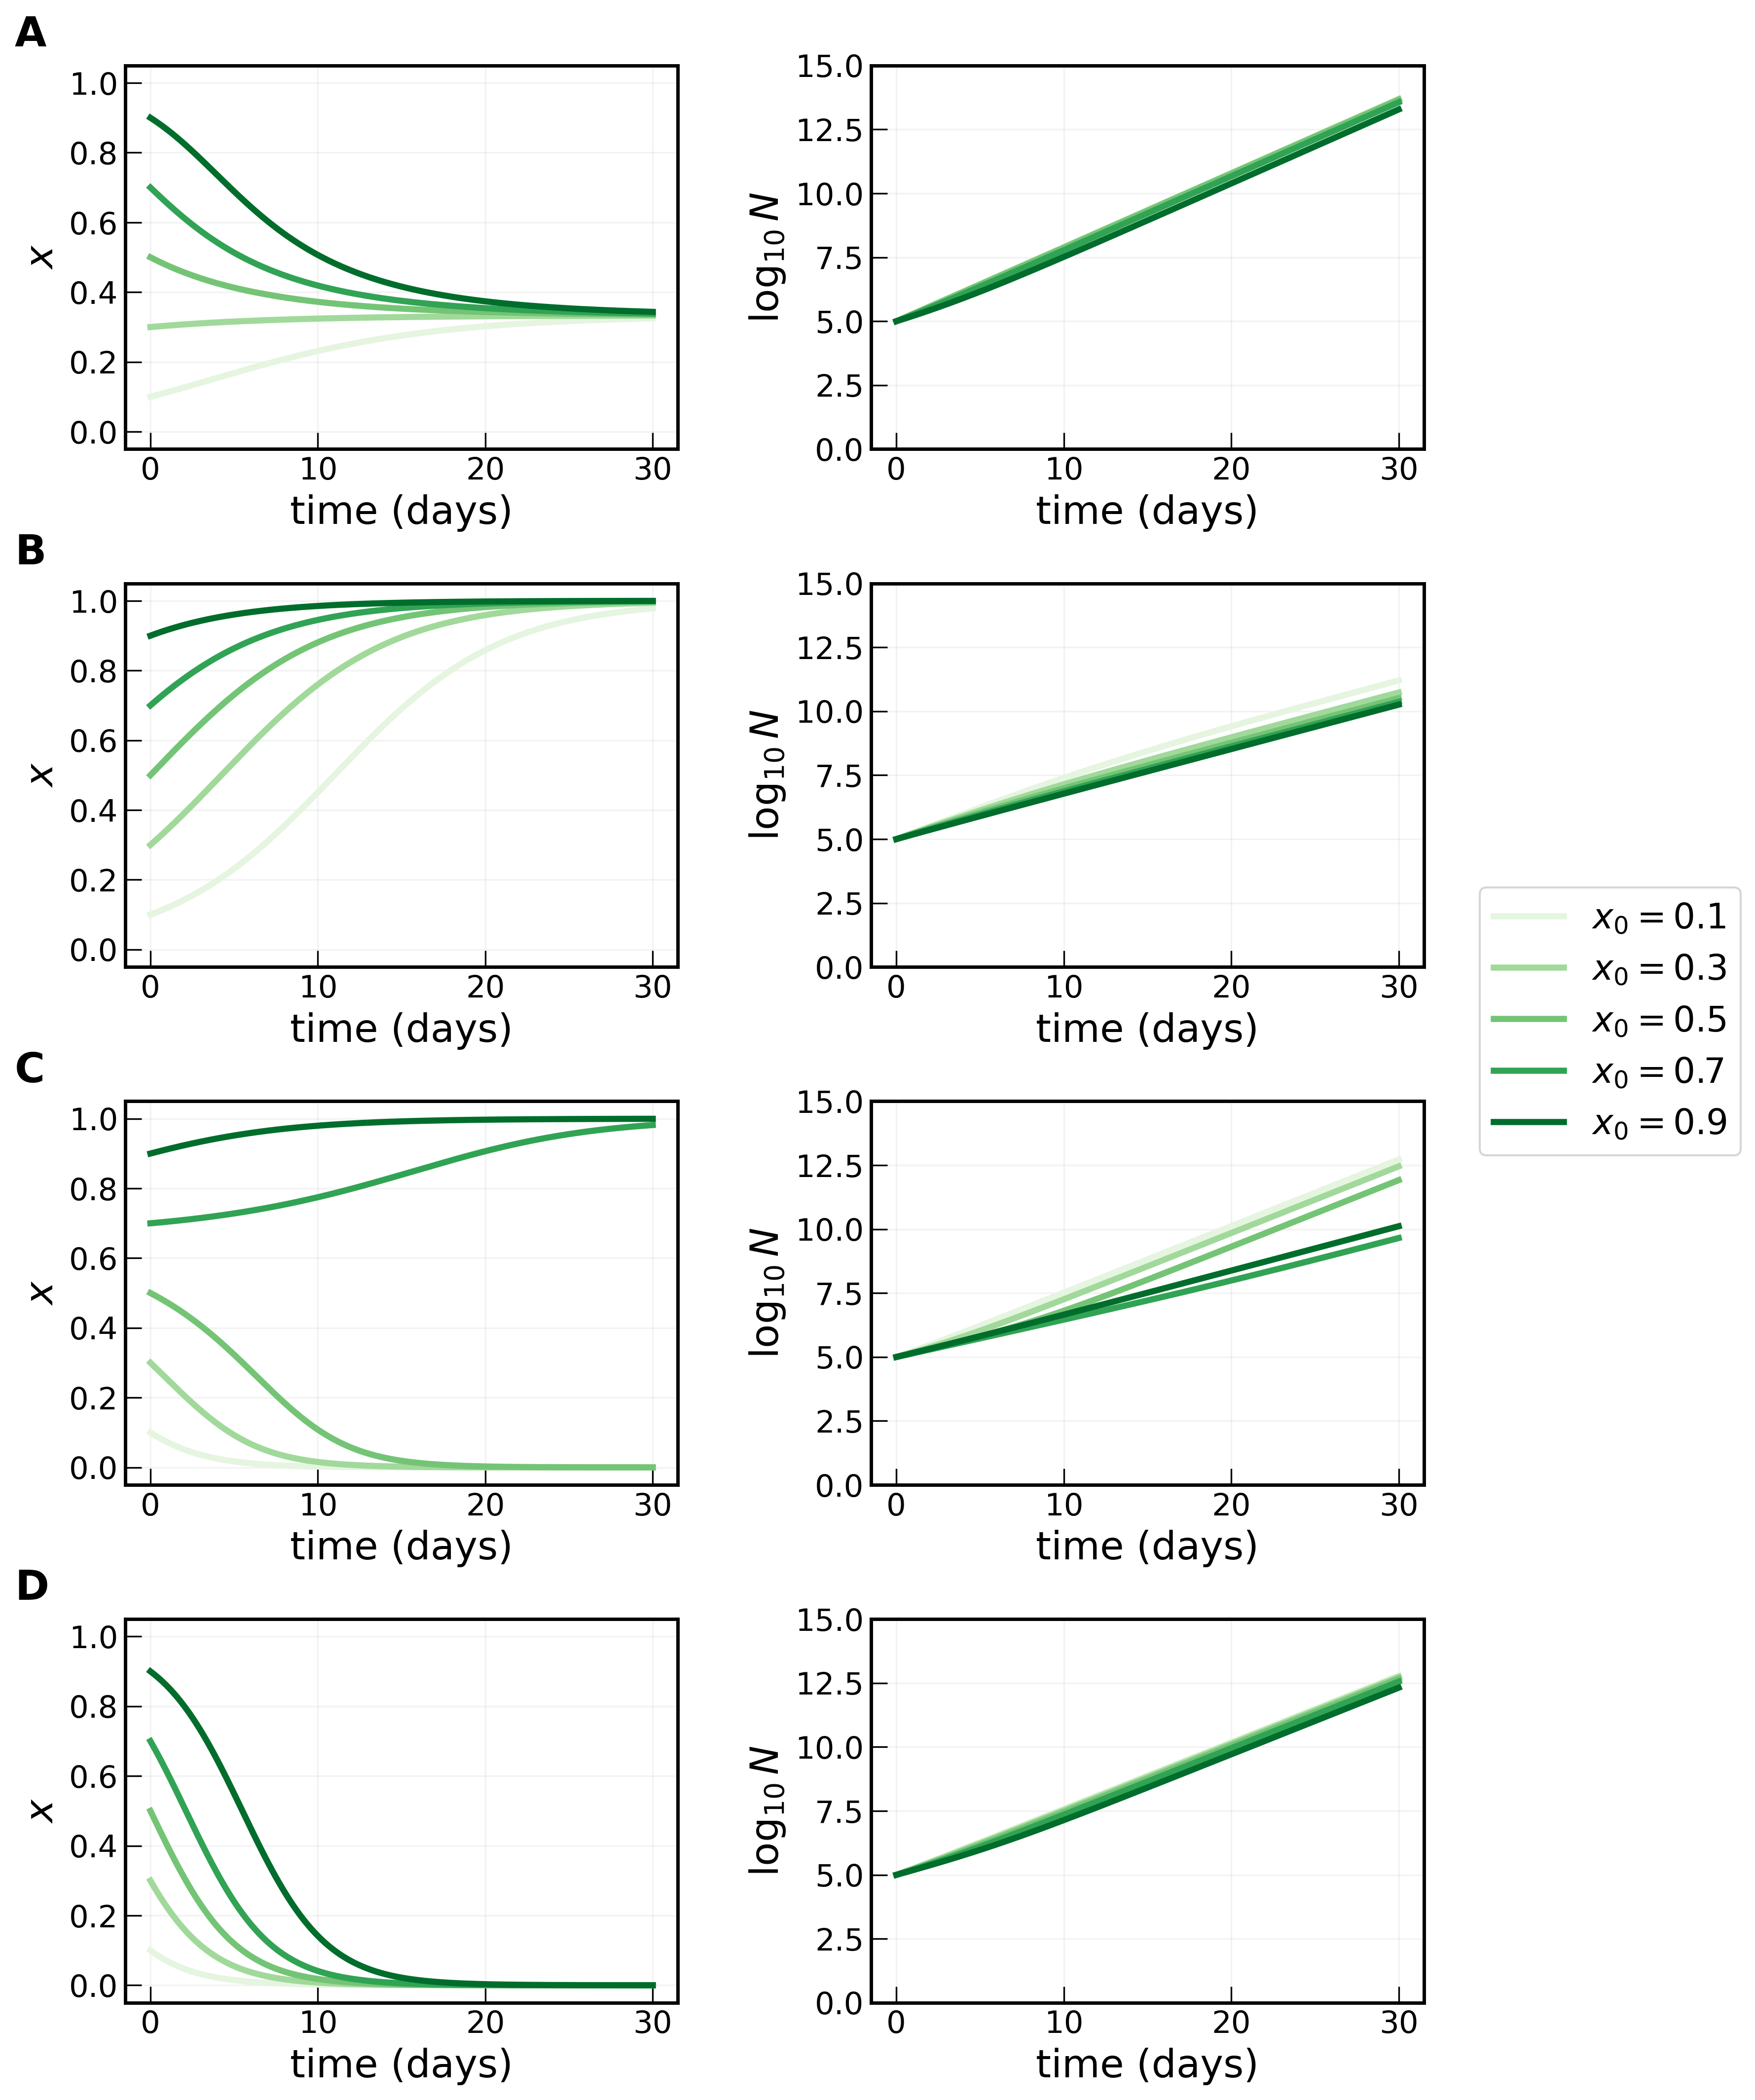

Saved successfully to: /content/drive/MyDrive/gamesfig2.png


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

plt.rcParams.update({
    "figure.dpi": 300,
    "font.size": 18,
    "axes.labelsize": 19,
    "xtick.labelsize": 15,
    "ytick.labelsize": 15,
    "legend.fontsize": 17,
    "axes.linewidth": 1.6,
    "lines.linewidth": 3,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.major.size": 8,
    "ytick.major.size": 8,
})

alpha, delta = 0.4, 0.6
x0_list = [0.1, 0.3, 0.5, 0.7, 0.9]

scenarios = [
    ("A", "Snowdrift",          0.8, 0.8),
    ("B", "Harmony",            0.8, 0.2),
    ("C", "Coordination",       0.2, 0.2),
    ("D", "Prisoner's Dilemma", 0.2, 0.8),
]

t0, t1, dt = 0.0, 30.0, 0.01
T = np.arange(t0, t1 + dt, dt)

N0 = 1e5

colors = [
    "#E5F5E0",
    "#A1D99B",
    "#74C476",
    "#31A354",
    "#006D2C",
]

def simulate(beta, gamma):
    def fL(x):
        return alpha * x + beta * (1 - x)

    def fF(x):
        return gamma * x + delta * (1 - x)

    def dNdt(N, x):
        return N * (x * fL(x) + (1 - x) * fF(x))

    def dxdt(x):
        return x * (1 - x) * (fL(x) - fF(x))

    def rk4_step(N, x, h):
        k1N = dNdt(N, x)
        k1x = dxdt(x)

        k2N = dNdt(N + 0.5*h*k1N, x + 0.5*h*k1x)
        k2x = dxdt(x + 0.5*h*k1x)

        k3N = dNdt(N + 0.5*h*k2N, x + 0.5*h*k2x)
        k3x = dxdt(x + 0.5*h*k2x)

        k4N = dNdt(N + h*k3N, x + h*k3x)
        k4x = dxdt(x + h*k3x)

        N_next = N + (h / 6) * (k1N + 2*k2N + 2*k3N + k4N)
        x_next = x + (h / 6) * (k1x + 2*k2x + 2*k3x + k4x)

        N_next = max(N_next, 1e-12)
        x_next = min(1.0, max(0.0, x_next))

        return N_next, x_next

    X, N = {}, {}

    for x0 in x0_list:
        x = x0
        n = N0

        x_vals = np.empty_like(T)
        n_vals = np.empty_like(T)

        x_vals[0] = x
        n_vals[0] = n

        for i in range(1, len(T)):
            n, x = rk4_step(n, x, dt)
            x_vals[i] = x
            n_vals[i] = n

        X[x0] = x_vals
        N[x0] = n_vals

    return X, N

results = {
    code: simulate(beta, gamma)
    for code, _, beta, gamma in scenarios
}

fig, axes = plt.subplots(4, 2, figsize=(13, 17), constrained_layout=False)
fig.subplots_adjust(right=0.80, wspace=0.35, hspace=0.35)

def add_panel_box(ax):
    ax.add_patch(Rectangle(
        (0, 0), 1, 1,
        transform=ax.transAxes,
        fill=False,
        linewidth=1.6,
        clip_on=False
    ))

def style_axes(ax, ylabel):
    ax.set_xlabel("time (days)")
    ax.set_ylabel(ylabel)
    ax.grid(True, alpha=0.15)

    for side in ["top", "right", "left", "bottom"]:
        ax.spines[side].set_linewidth(1.6)

panel_letters = ["A", "B", "C", "D"]

for row, (code, _, _, _) in enumerate(scenarios):
    X, NN = results[code]

    axL = axes[row, 0]
    axR = axes[row, 1]

    for x0, c in zip(x0_list, colors):
        axL.plot(T, X[x0], color=c, label=f"$x_0={x0}$")
        axR.plot(T, np.log10(NN[x0]), color=c)

    style_axes(axL, r"$x$")
    style_axes(axR, r"$\log_{10} N$")

    axL.set_ylim(-0.05, 1.05)
    axR.set_ylim(0, 15)

    add_panel_box(axL)
    add_panel_box(axR)

    axL.annotate(
        panel_letters[row],
        xy=(-0.20, 1.05),
        xycoords="axes fraction",
        fontsize=20,
        fontweight="bold",
        annotation_clip=False
    )

handles, labels = axes[0, 0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    loc="center left",
    bbox_to_anchor=(0.82, 0.5),
    frameon=True
)

save_path = "/content/drive/MyDrive/gamesfig2.png"

plt.savefig(save_path, format="png", bbox_inches="tight")
plt.show()

print(f"Saved successfully to: {save_path}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


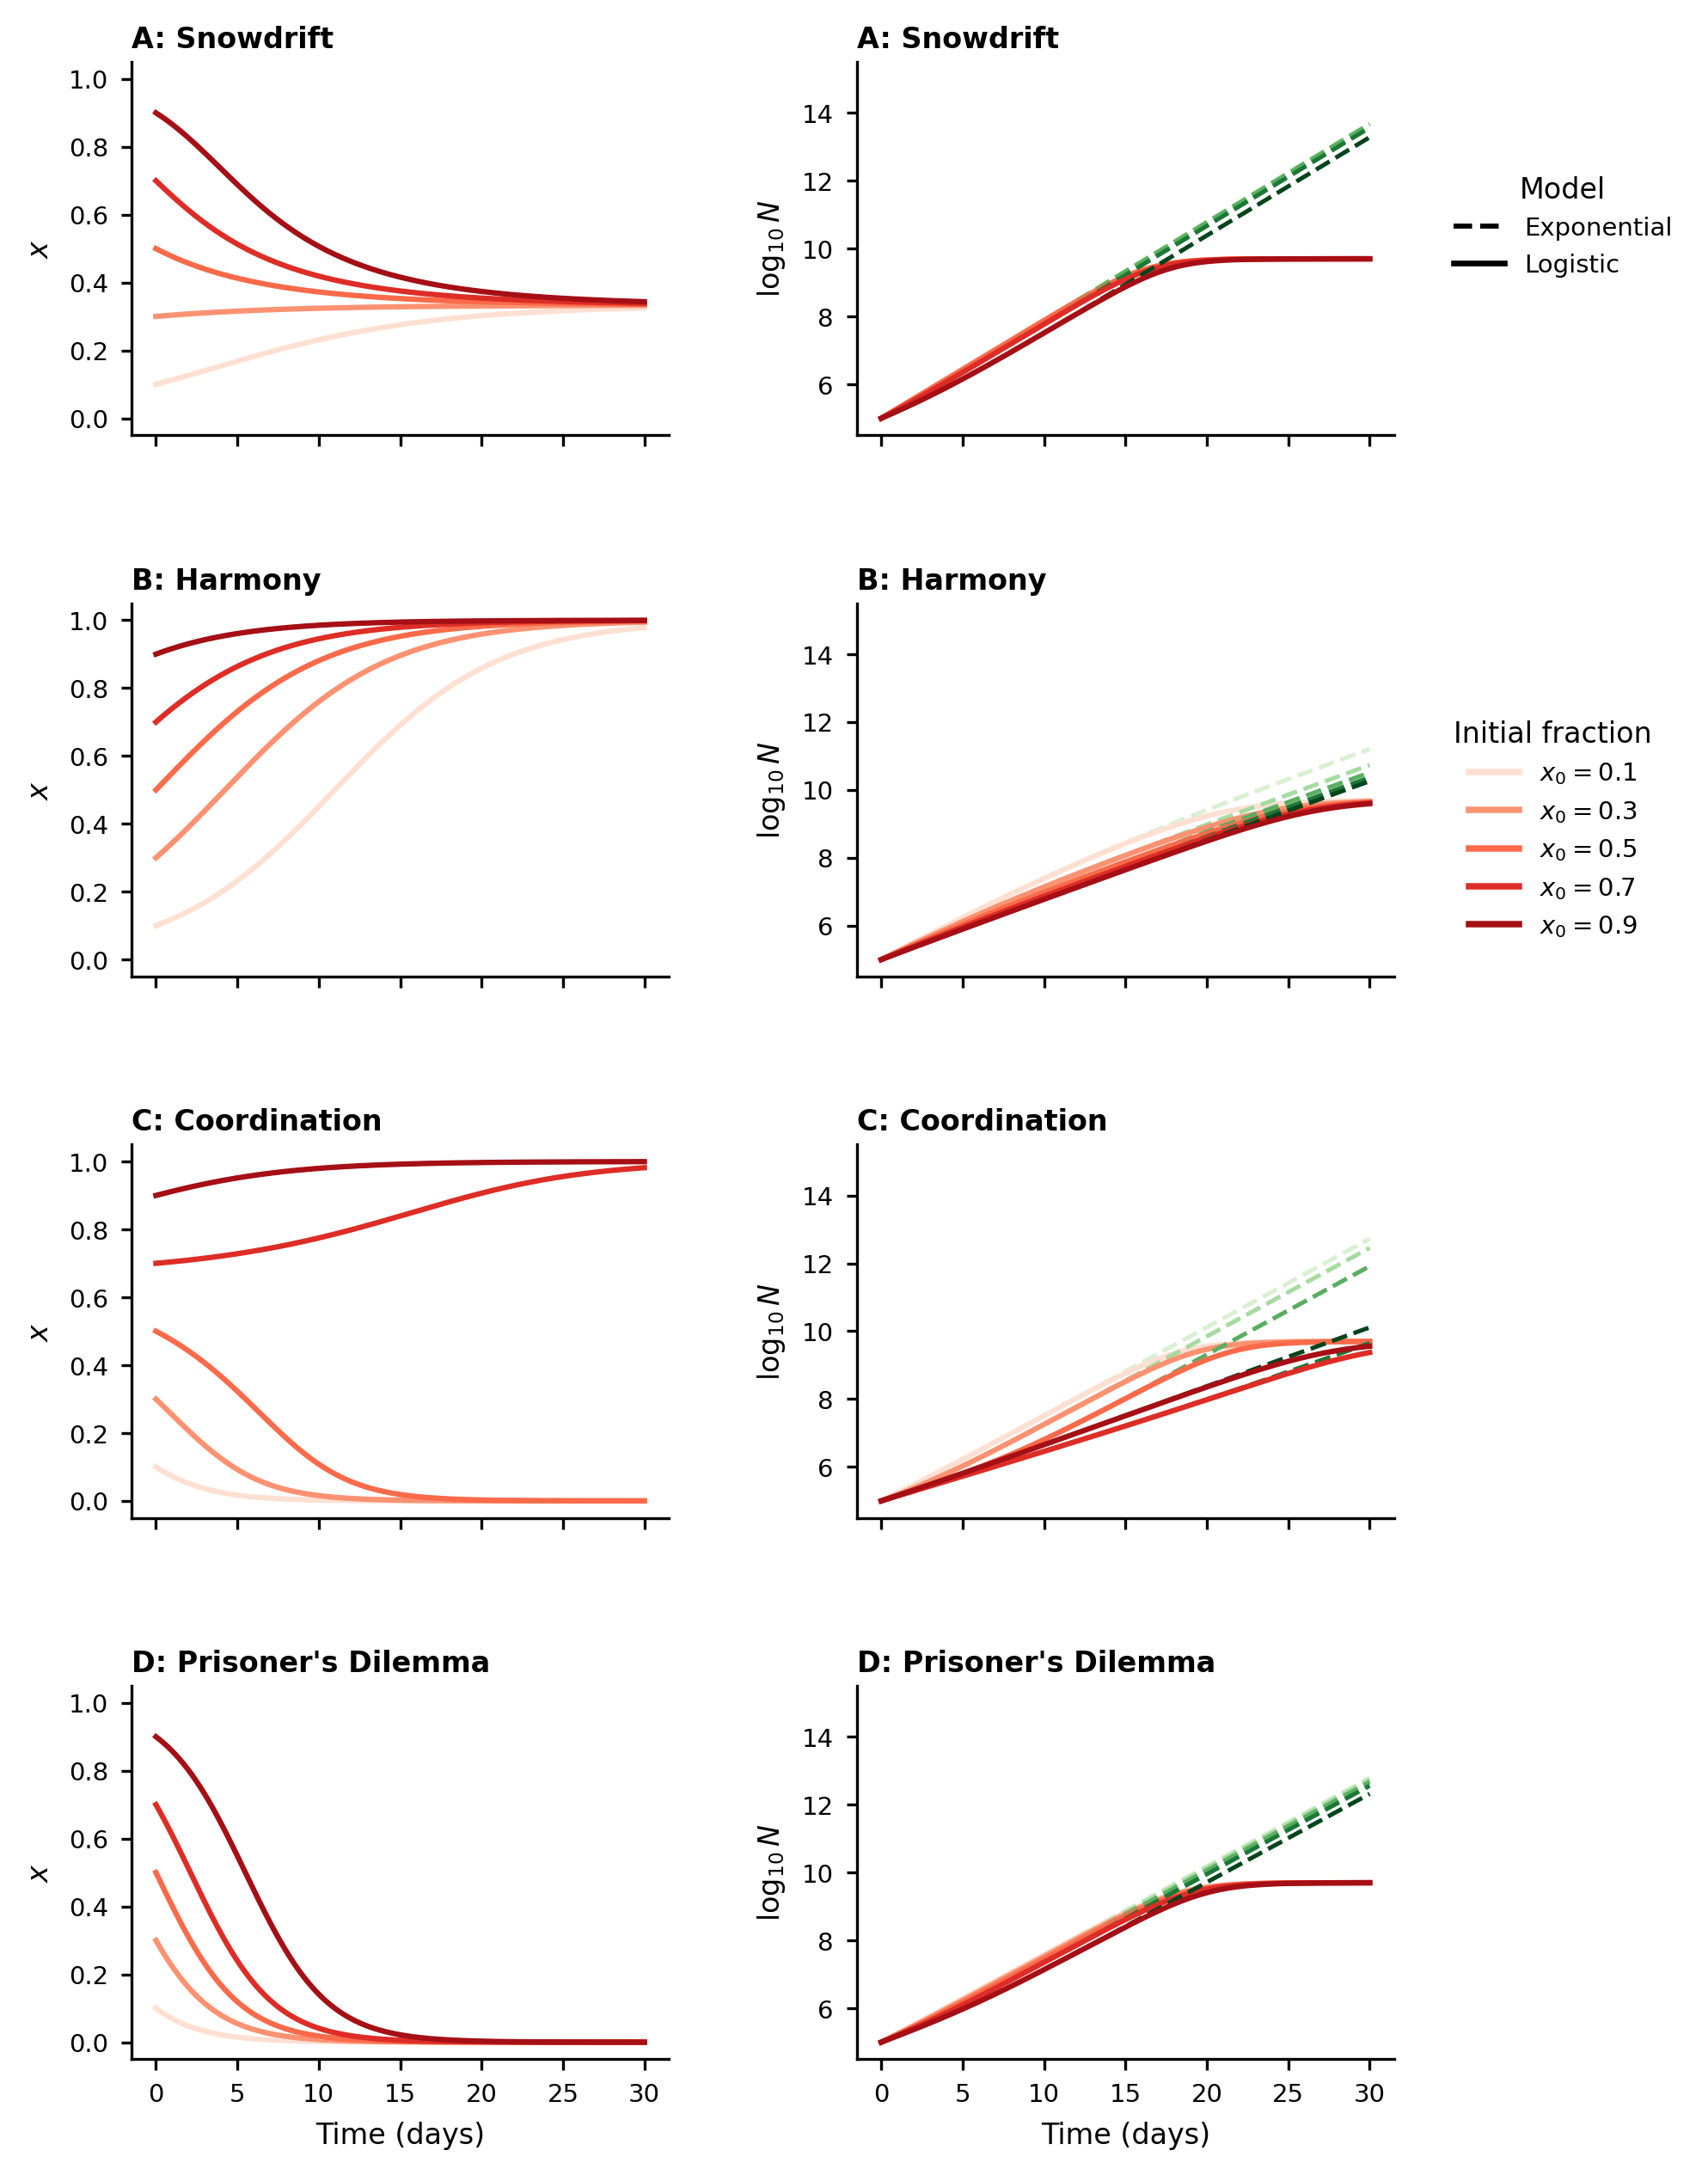

Saved PNG: /content/drive/MyDrive/games_exp_vs_logistic_NatureStyle.png
Saved PDF: /content/drive/MyDrive/games_exp_vs_logistic_NatureStyle.pdf


In [ ]:
from google.colab import drive
drive.mount("/content/drive")

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

plt.rcParams.update({
    "figure.dpi": 300,
    "savefig.dpi": 600,
    "font.family": "Arial",
    "font.size": 8,
    "axes.labelsize": 8,
    "axes.titlesize": 8,
    "xtick.labelsize": 7,
    "ytick.labelsize": 7,
    "legend.fontsize": 7,
    "axes.linewidth": 0.8,
    "lines.linewidth": 1.4,
    "xtick.direction": "out",
    "ytick.direction": "out",
    "xtick.major.size": 3,
    "ytick.major.size": 3,
    "xtick.major.width": 0.8,
    "ytick.major.width": 0.8,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})

alpha, delta = 0.4, 0.6
K = 5e9
N0 = 1e5

x0_list = [0.1, 0.3, 0.5, 0.7, 0.9]

scenarios = [
    ("A", "Snowdrift",          0.8, 0.8),
    ("B", "Harmony",            0.8, 0.2),
    ("C", "Coordination",       0.2, 0.2),
    ("D", "Prisoner's Dilemma", 0.2, 0.8),
]

t0, t1, dt = 0.0, 30.0, 0.01
T = np.arange(t0, t1 + dt, dt)

colors_exp = ["#D9F0D3", "#A6DBA0", "#5AAE61", "#1B7837", "#00441B"]
colors_log = ["#FEE0D2", "#FC9272", "#FB6A4A", "#DE2D26", "#A50F15"]

def simulate(beta, gamma, carrying_capacity=False):
    def fL(x):
        return alpha * x + beta * (1 - x)

    def fF(x):
        return gamma * x + delta * (1 - x)

    def growth_rate(x):
        return x * fL(x) + (1 - x) * fF(x)

    def dNdt(N, x):
        if carrying_capacity:
            return N * growth_rate(x) * (1 - N / K)
        return N * growth_rate(x)

    def dxdt(x):
        return x * (1 - x) * (fL(x) - fF(x))

    def rk4_step(N, x, h):
        k1N = dNdt(N, x)
        k1x = dxdt(x)

        k2N = dNdt(N + 0.5 * h * k1N, x + 0.5 * h * k1x)
        k2x = dxdt(x + 0.5 * h * k1x)

        k3N = dNdt(N + 0.5 * h * k2N, x + 0.5 * h * k2x)
        k3x = dxdt(x + 0.5 * h * k2x)

        k4N = dNdt(N + h * k3N, x + h * k3x)
        k4x = dxdt(x + h * k3x)

        N_next = N + (h / 6) * (k1N + 2*k2N + 2*k3N + k4N)
        x_next = x + (h / 6) * (k1x + 2*k2x + 2*k3x + k4x)

        N_next = max(N_next, 1e-12)
        x_next = min(1.0, max(0.0, x_next))

        return N_next, x_next

    X, N = {}, {}

    for x0 in x0_list:
        x = x0
        n = N0

        x_vals = np.empty_like(T)
        n_vals = np.empty_like(T)

        x_vals[0] = x
        n_vals[0] = n

        for i in range(1, len(T)):
            n, x = rk4_step(n, x, dt)
            x_vals[i] = x
            n_vals[i] = n

        X[x0] = x_vals
        N[x0] = n_vals

    return X, N

results_exp = {}
results_log = {}

for code, name, beta, gamma in scenarios:
    results_exp[code] = simulate(beta, gamma, carrying_capacity=False)
    results_log[code] = simulate(beta, gamma, carrying_capacity=True)

fig, axes = plt.subplots(
    4,
    2,
    figsize=(7.2, 8.8),
    sharex=True,
)

fig.subplots_adjust(
    left=0.10,
    right=0.78,
    bottom=0.08,
    top=0.96,
    wspace=0.35,
    hspace=0.45,
)

for row, (code, name, beta, gamma) in enumerate(scenarios):
    X_exp, N_exp = results_exp[code]
    X_log, N_log = results_log[code]

    ax_x = axes[row, 0]
    ax_n = axes[row, 1]

    for x0, c_exp, c_log in zip(x0_list, colors_exp, colors_log):
        ax_x.plot(T, X_exp[x0], color=c_exp, linestyle="--", linewidth=1.2)
        ax_x.plot(T, X_log[x0], color=c_log, linestyle="-", linewidth=1.5)

        ax_n.plot(T, np.log10(N_exp[x0]), color=c_exp, linestyle="--", linewidth=1.2)
        ax_n.plot(T, np.log10(N_log[x0]), color=c_log, linestyle="-", linewidth=1.5)

    ax_x.set_ylim(-0.05, 1.05)
    ax_n.set_ylim(4.5, 15.5)

    ax_x.set_ylabel(r"$x$")
    ax_n.set_ylabel(r"$\log_{10} N$")

    ax_x.set_title(f"{code}: {name}", loc="left", fontweight="bold", pad=4)
    ax_n.set_title(f"{code}: {name}", loc="left", fontweight="bold", pad=4)

    ax_x.spines["top"].set_visible(False)
    ax_x.spines["right"].set_visible(False)
    ax_n.spines["top"].set_visible(False)
    ax_n.spines["right"].set_visible(False)

    ax_x.tick_params(length=3, width=0.8)
    ax_n.tick_params(length=3, width=0.8)

    ax_x.grid(False)
    ax_n.grid(False)

axes[-1, 0].set_xlabel("Time (days)")
axes[-1, 1].set_xlabel("Time (days)")

model_handles = [
    Line2D([0], [0], color="black", linestyle="--", linewidth=1.4, label="Exponential"),
    Line2D([0], [0], color="black", linestyle="-", linewidth=1.6, label="Logistic"),
]

x0_handles = [
    Line2D([0], [0], color=c, linestyle="-", linewidth=1.8, label=rf"$x_0={x0}$")
    for x0, c in zip(x0_list, colors_log)
]

fig.legend(
    handles=model_handles,
    loc="upper left",
    bbox_to_anchor=(0.80, 0.92),
    frameon=False,
    title="Model",
    title_fontsize=8,
)

fig.legend(
    handles=x0_handles,
    loc="upper left",
    bbox_to_anchor=(0.80, 0.68),
    frameon=False,
    title="Initial fraction",
    title_fontsize=8,
)

save_png = "/content/drive/MyDrive/games_exp_vs_logistic_NatureStyle.png"
save_pdf = "/content/drive/MyDrive/games_exp_vs_logistic_NatureStyle.pdf"

plt.savefig(save_png, bbox_inches="tight")
plt.savefig(save_pdf, bbox_inches="tight")
plt.show()

print(f"Saved PNG: {save_png}")
print(f"Saved PDF: {save_pdf}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


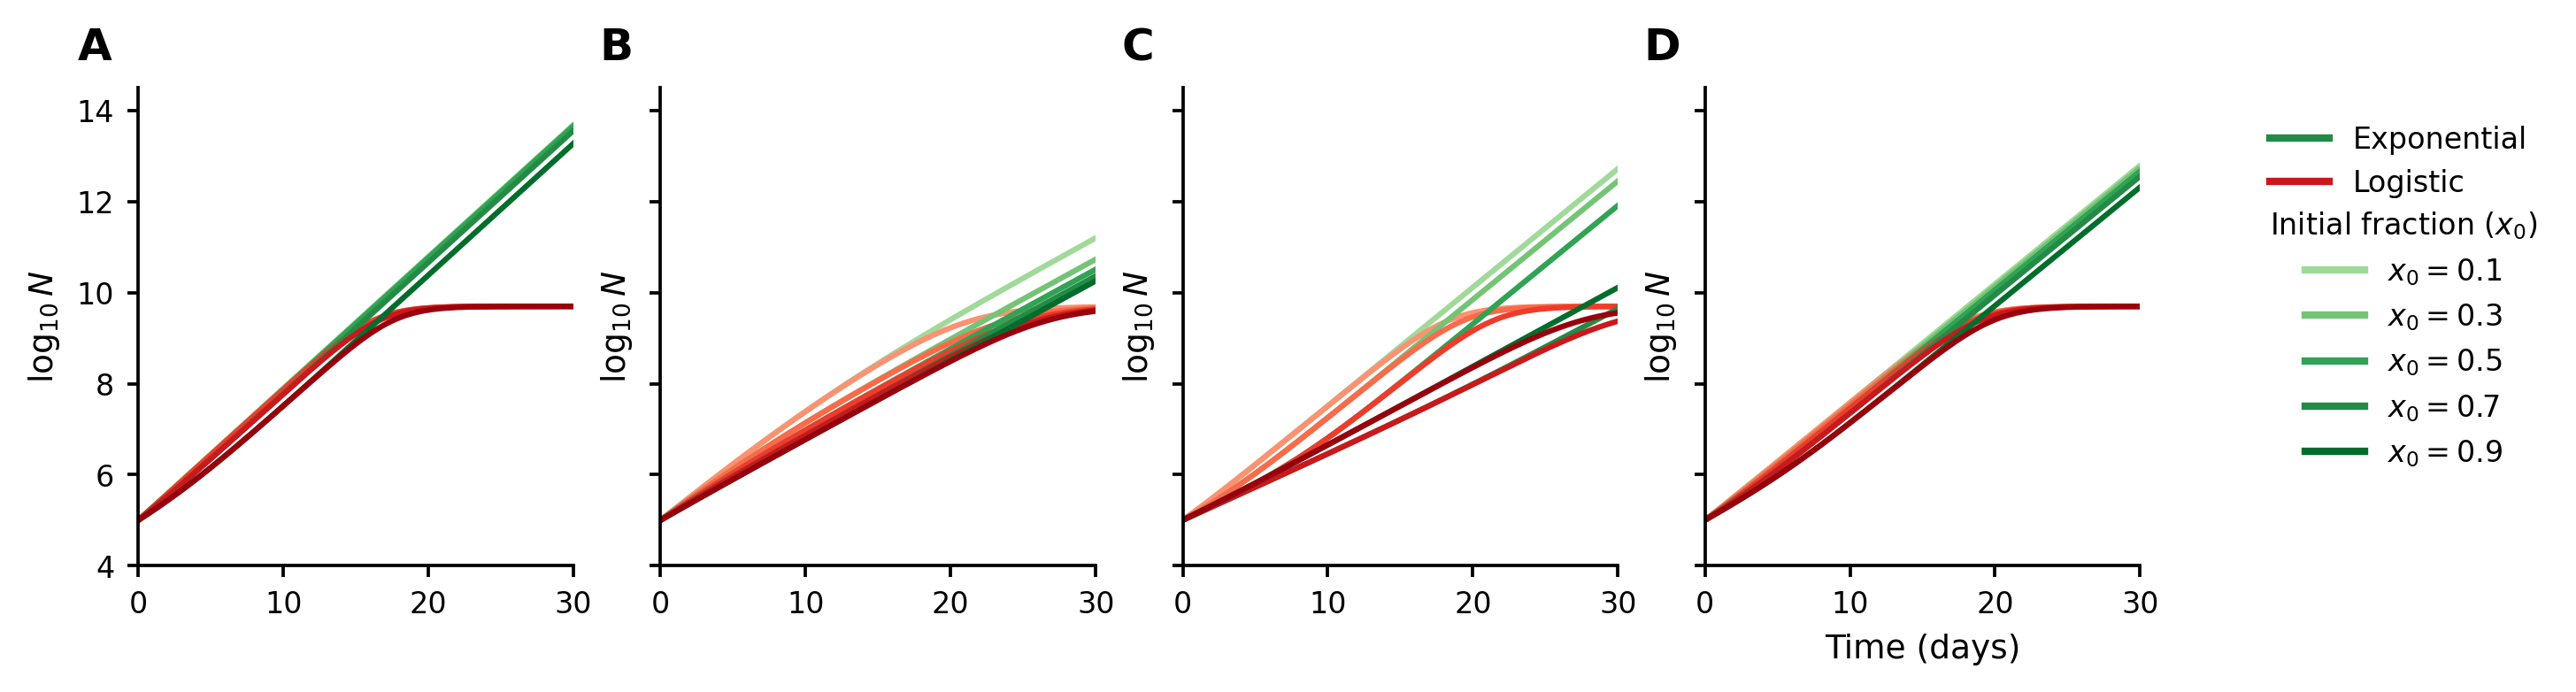

Saved PNG: /content/drive/MyDrive/games_1x4_log10_N_exp_vs_logistic.png
Saved PDF: /content/drive/MyDrive/games_1x4_log10_N_exp_vs_logistic.pdf


In [ ]:
from google.colab import drive
drive.mount("/content/drive")

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

plt.rcParams.update({
    "figure.dpi": 300,
    "savefig.dpi": 600,
    "font.family": "Arial",
    "font.size": 8,
    "axes.labelsize": 9,
    "axes.titlesize": 9,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "legend.fontsize": 8,
    "axes.linewidth": 0.9,
    "lines.linewidth": 1.6,
    "xtick.direction": "out",
    "ytick.direction": "out",
    "xtick.major.size": 3,
    "ytick.major.size": 3,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})

alpha, delta = 0.4, 0.6
K = 5e9
N0 = 1e5

x0_list = [0.1, 0.3, 0.5, 0.7, 0.9]

scenarios = [
    ("A", 0.8, 0.8),
    ("B", 0.8, 0.2),
    ("C", 0.2, 0.2),
    ("D", 0.2, 0.8),
]

T = np.arange(0, 30.01, 0.01)
dt = T[1] - T[0]

green_colors = ["#A1D99B", "#74C476", "#31A354", "#238B45", "#006D2C"]
red_colors   = ["#FC9272", "#FB6A4A", "#EF3B2C", "#CB181D", "#99000D"]

def simulate(beta, gamma, logistic=False):
    def fL(x):
        return alpha * x + beta * (1 - x)

    def fF(x):
        return gamma * x + delta * (1 - x)

    def growth_rate(x):
        return x * fL(x) + (1 - x) * fF(x)

    def dNdt(N, x):
        if logistic:
            return N * growth_rate(x) * (1 - N / K)
        return N * growth_rate(x)

    def dxdt(x):
        return x * (1 - x) * (fL(x) - fF(x))

    def rk4_step(N, x):
        k1N, k1x = dNdt(N, x), dxdt(x)
        k2N, k2x = dNdt(N + 0.5*dt*k1N, x + 0.5*dt*k1x), dxdt(x + 0.5*dt*k1x)
        k3N, k3x = dNdt(N + 0.5*dt*k2N, x + 0.5*dt*k2x), dxdt(x + 0.5*dt*k2x)
        k4N, k4x = dNdt(N + dt*k3N, x + dt*k3x), dxdt(x + dt*k3x)

        N_next = N + (dt / 6) * (k1N + 2*k2N + 2*k3N + k4N)
        x_next = x + (dt / 6) * (k1x + 2*k2x + 2*k3x + k4x)

        return max(N_next, 1e-12), min(1.0, max(0.0, x_next))

    results = {}

    for x0 in x0_list:
        N = np.empty_like(T)
        x = np.empty_like(T)

        N[0] = N0
        x[0] = x0

        for i in range(1, len(T)):
            N[i], x[i] = rk4_step(N[i-1], x[i-1])

        results[x0] = N

    return results

fig, axes = plt.subplots(
    1, 4,
    figsize=(13, 2),
    sharex=True,
    sharey=True
)

fig.subplots_adjust(
    left=0.14,
    right=0.72,
    bottom=0.08,
    top=0.98,
    hspace=0.45
)

for ax, (panel, beta, gamma) in zip(axes, scenarios):
    exp_results = simulate(beta, gamma, logistic=False)
    log_results = simulate(beta, gamma, logistic=True)

    for x0, g, r in zip(x0_list, green_colors, red_colors):
        ax.plot(T, np.log10(exp_results[x0]), color=g, linestyle="-", linewidth=1.5)
        ax.plot(T, np.log10(log_results[x0]), color=r, linestyle="-", linewidth=1.5)

    ax.set_ylabel(r"$\log_{10} N$")
    ax.set_ylim(4, 14.5)
    ax.set_xlim(0, 30)

    ax.text(
        -0.14, 1.04, panel,
        transform=ax.transAxes,
        fontsize=12,
        fontweight="bold",
        va="bottom",
        ha="left"
    )

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.tick_params(width=0.9, length=3)

axes[-1].set_xlabel("Time (days)")

model_handles = [
    Line2D([0], [0], color="#238B45", linestyle="-", linewidth=2, label="Exponential"),
    Line2D([0], [0], color="#CB181D", linestyle="-", linewidth=2, label="Logistic"),
]

x0_handles = [
    Line2D([0], [0], color=c, linestyle="-", linewidth=2, label=rf"$x_0={x0}$")
    for x0, c in zip(x0_list, green_colors)
]

fig.legend(
    handles=model_handles,
    loc="upper left",
    bbox_to_anchor=(0.75, 0.96),
    frameon=False
)

fig.legend(
    handles=x0_handles,
    title=r"Initial fraction ($x_0$)",
    loc="upper left",
    bbox_to_anchor=(0.75, 0.80),
    frameon=False
)

save_png = "/content/drive/MyDrive/games_1x4_log10_N_exp_vs_logistic.png"
save_pdf = "/content/drive/MyDrive/games_1x4_log10_N_exp_vs_logistic.pdf"

plt.savefig(save_png, bbox_inches="tight")
plt.savefig(save_pdf, bbox_inches="tight")
plt.show()

print(f"Saved PNG: {save_png}")
print(f"Saved PDF: {save_pdf}")

A Snowdrift, x0=0.001: x(10)=0.3333, N(10)=1.000e+09, N(10)/K=1.000
A Snowdrift, x0=0.3: x(10)=0.3333, N(10)=1.000e+09, N(10)/K=1.000
A Snowdrift, x0=0.5: x(10)=0.3333, N(10)=1.000e+09, N(10)/K=1.000
A Snowdrift, x0=0.7: x(10)=0.3333, N(10)=1.000e+09, N(10)/K=1.000
A Snowdrift, x0=0.999: x(10)=0.3333, N(10)=1.000e+09, N(10)/K=1.000
B Harmony, x0=0.001: x(10)=1.0000, N(10)=1.000e+09, N(10)/K=1.000
B Harmony, x0=0.3: x(10)=1.0000, N(10)=1.000e+09, N(10)/K=1.000
B Harmony, x0=0.5: x(10)=1.0000, N(10)=1.000e+09, N(10)/K=1.000
B Harmony, x0=0.7: x(10)=1.0000, N(10)=1.000e+09, N(10)/K=1.000
B Harmony, x0=0.999: x(10)=1.0000, N(10)=1.000e+09, N(10)/K=1.000
C Coordination, x0=0.001: x(10)=0.0000, N(10)=1.000e+09, N(10)/K=1.000
C Coordination, x0=0.3: x(10)=0.0000, N(10)=1.000e+09, N(10)/K=1.000
C Coordination, x0=0.5: x(10)=0.0000, N(10)=1.000e+09, N(10)/K=1.000
C Coordination, x0=0.7: x(10)=1.0000, N(10)=1.000e+09, N(10)/K=1.000
C Coordination, x0=0.999: x(10)=1.0000, N(10)=1.000e+09, N(10)/K

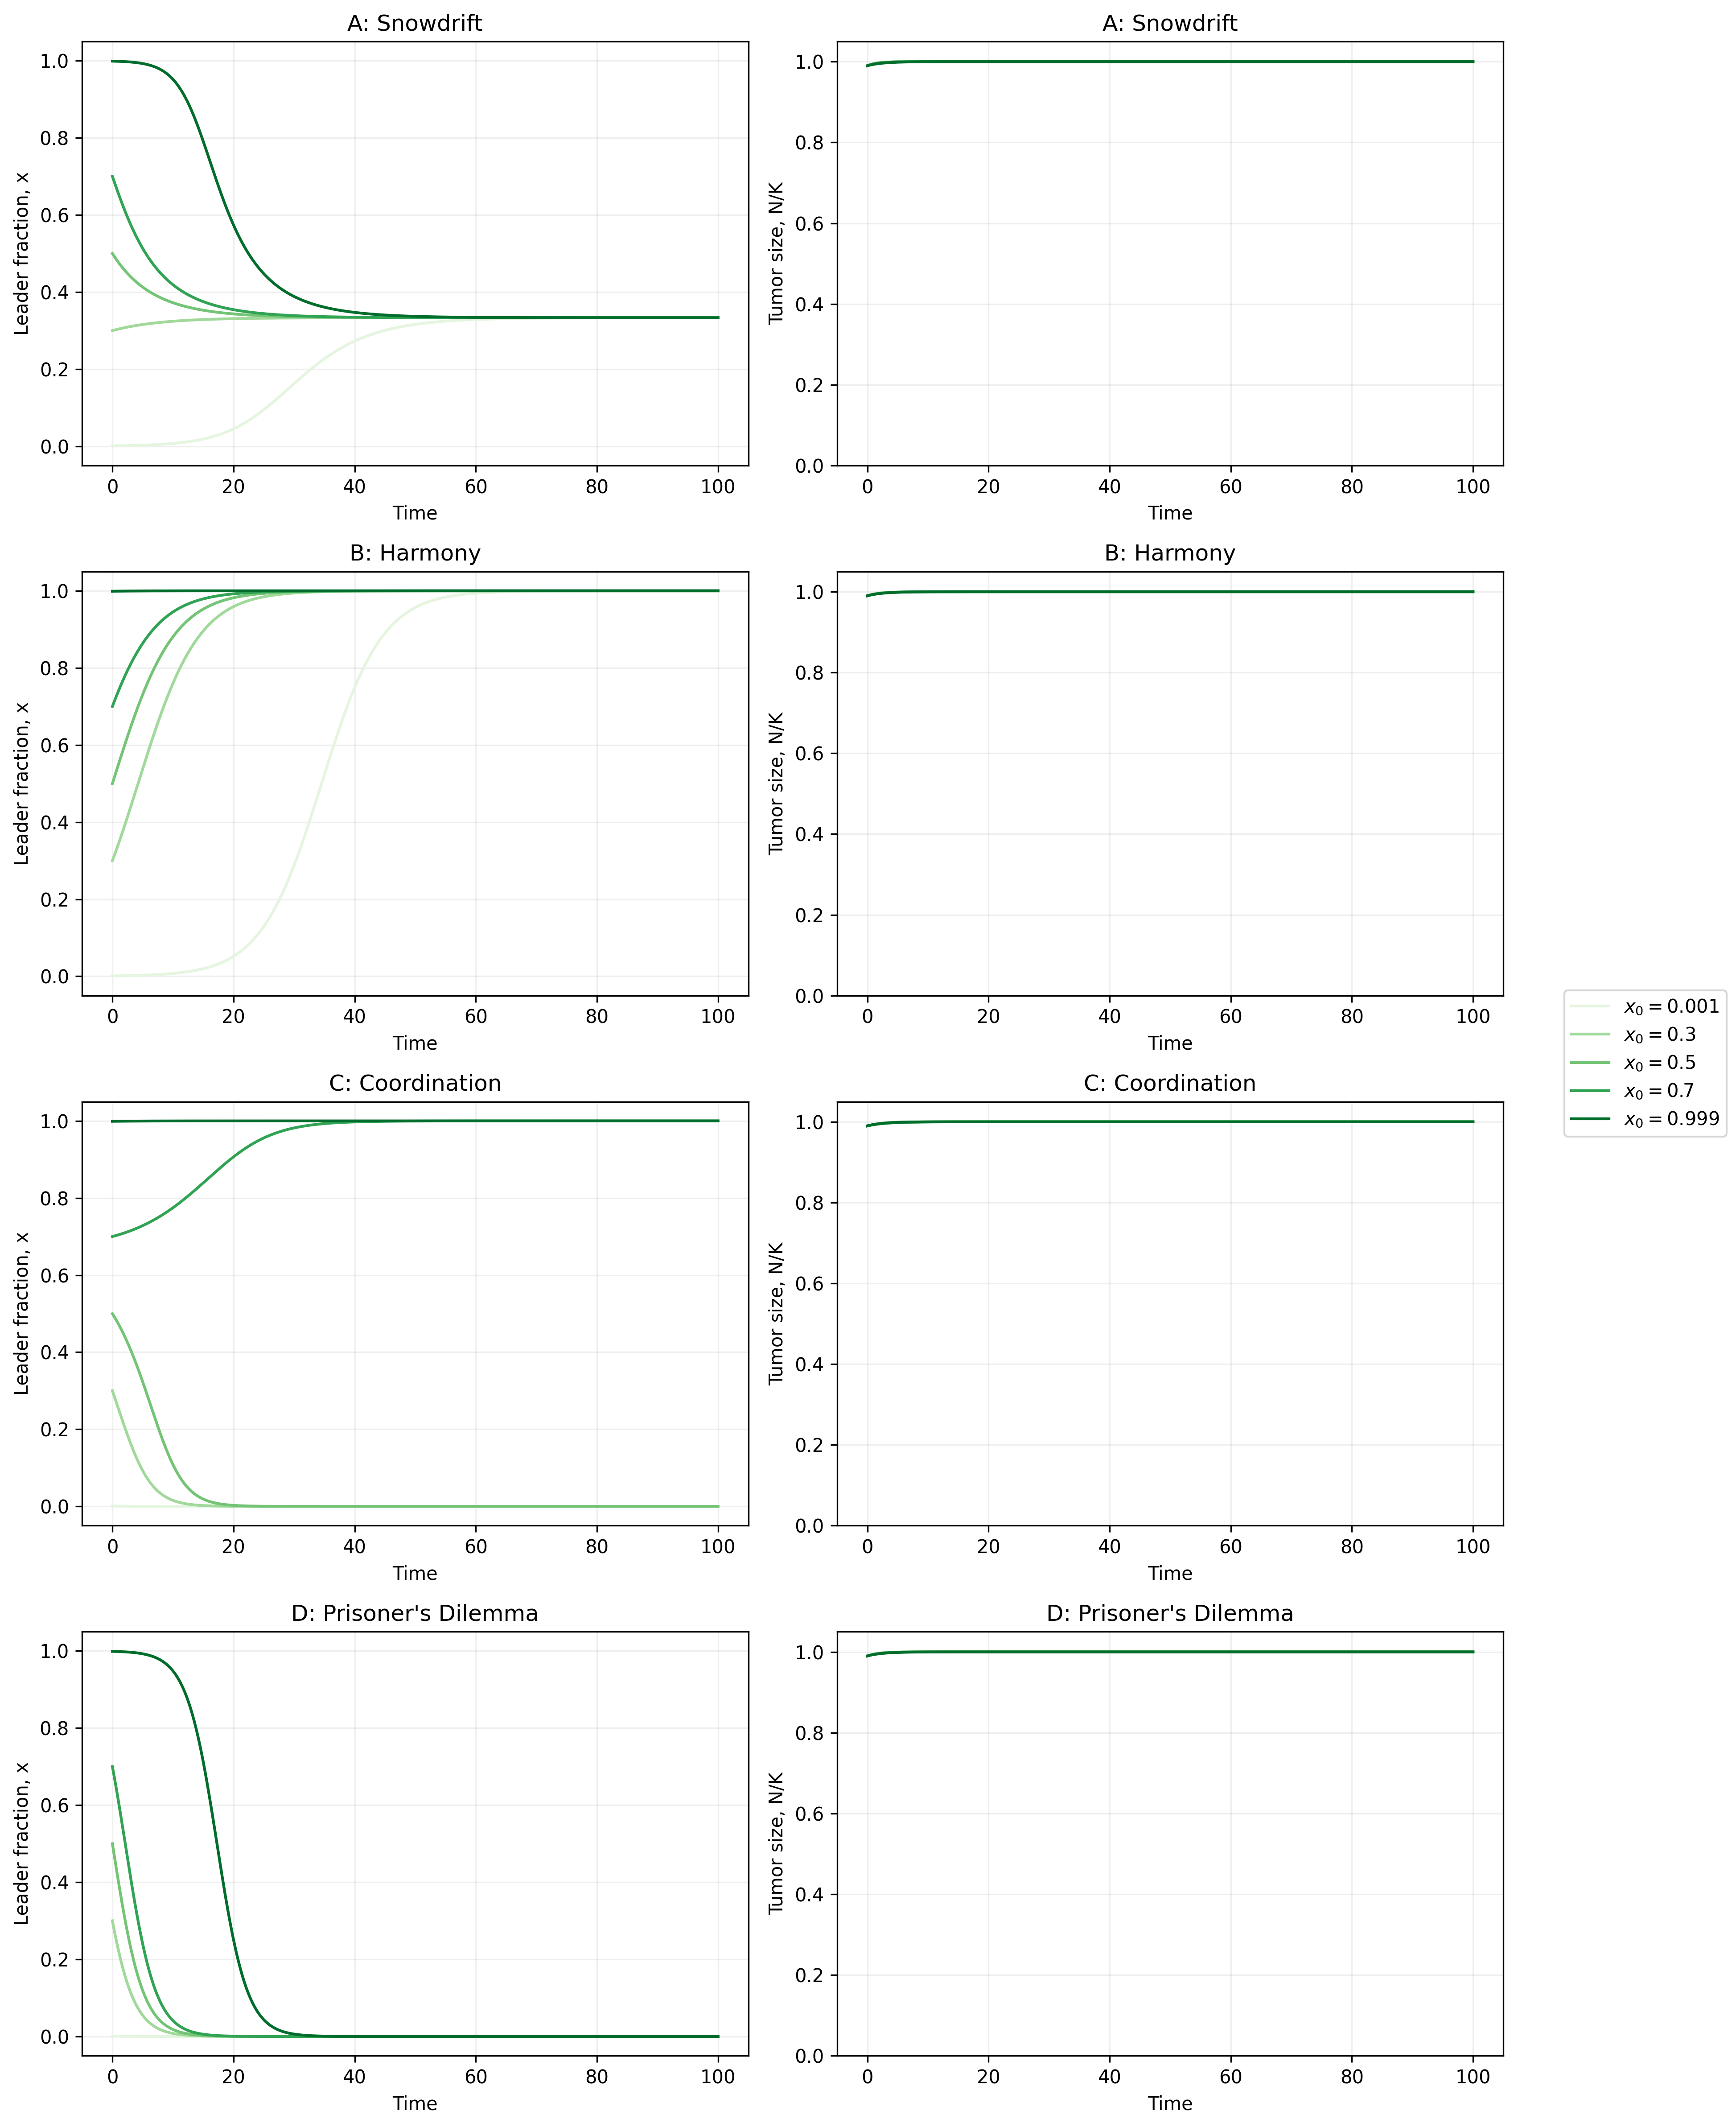

In [3]:
import numpy as np
import matplotlib.pyplot as plt

alpha, delta = 0.4, 0.6
K = 1e9
N0 = 9.9e8

x0_list = [0.001, 0.3, 0.5, 0.7, 0.999]

scenarios = [
    ("A", "Snowdrift",          0.8, 0.8),
    ("B", "Harmony",            0.8, 0.2),
    ("C", "Coordination",       0.2, 0.2),
    ("D", "Prisoner's Dilemma", 0.2, 0.8),
]

T = np.linspace(0,100, 1001)
dt = T[1] - T[0]

colors = ["#E5F5E0", "#A1D99B", "#74C476", "#31A354", "#006D2C"]

def simulate(beta, gamma, x0):
    def fL(x):
        return alpha * x + beta * (1 - x)

    def fF(x):
        return gamma * x + delta * (1 - x)

    def dNdt(N, x):
        growth = x * fL(x) + (1 - x) * fF(x)
        return N * growth * (1 - N / K)

    def dxdt(x):
        return x * (1 - x) * (fL(x) - fF(x))

    N = np.zeros_like(T)
    x = np.zeros_like(T)

    N[0] = N0
    x[0] = x0

    for i in range(1, len(T)):
        N_curr = N[i - 1]
        x_curr = x[i - 1]

        k1N = dNdt(N_curr, x_curr)
        k1x = dxdt(x_curr)

        k2N = dNdt(N_curr + 0.5 * dt * k1N, x_curr + 0.5 * dt * k1x)
        k2x = dxdt(x_curr + 0.5 * dt * k1x)

        k3N = dNdt(N_curr + 0.5 * dt * k2N, x_curr + 0.5 * dt * k2x)
        k3x = dxdt(x_curr + 0.5 * dt * k2x)

        k4N = dNdt(N_curr + dt * k3N, x_curr + dt * k3x)
        k4x = dxdt(x_curr + dt * k3x)

        N[i] = N_curr + (dt / 6) * (k1N + 2*k2N + 2*k3N + k4N)
        x[i] = x_curr + (dt / 6) * (k1x + 2*k2x + 2*k3x + k4x)

        N[i] = max(0, min(N[i], K))
        x[i] = max(0, min(x[i], 1))

    return x, N

fig, axes = plt.subplots(4, 2, figsize=(13, 16), dpi=300)

for row, (code, name, beta, gamma) in enumerate(scenarios):
    ax_x = axes[row, 0]
    ax_N = axes[row, 1]

    for x0, color in zip(x0_list, colors):
        x, N = simulate(beta, gamma, x0)

        ax_x.plot(T, x, color=color, label=f"$x_0={x0}$")
        ax_N.plot(T, N / K, color=color)

        print(
            f"{code} {name}, x0={x0}: "
            f"x(10)={x[-1]:.4f}, "
            f"N(10)={N[-1]:.3e}, "
            f"N(10)/K={N[-1]/K:.3f}"
        )

    ax_x.set_title(f"{code}: {name}")
    ax_N.set_title(f"{code}: {name}")

    ax_x.set_ylabel("Leader fraction, x")
    ax_N.set_ylabel("Tumor size, N/K")

    ax_x.set_xlabel("Time")
    ax_N.set_xlabel("Time")

    ax_x.set_ylim(-0.05, 1.05)
    ax_N.set_ylim(0, 1.05)

    ax_x.grid(alpha=0.2)
    ax_N.grid(alpha=0.2)

handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="center right", frameon=True)

plt.tight_layout(rect=[0, 0, 0.88, 1])
plt.show()

A Snowdrift, x0=0.001: x(100)=0.0027, N(100)=1.000e+09, N(100)/K=1.0000
A Snowdrift, x0=0.3: x(100)=0.3146, N(100)=1.000e+09, N(100)/K=1.0000
A Snowdrift, x0=0.5: x(100)=0.4181, N(100)=1.000e+09, N(100)/K=1.0000
A Snowdrift, x0=0.7: x(100)=0.5182, N(100)=1.000e+09, N(100)/K=1.0000
A Snowdrift, x0=0.999: x(100)=0.9815, N(100)=1.000e+09, N(100)/K=1.0000
B Harmony, x0=0.001: x(100)=0.0027, N(100)=1.000e+09, N(100)/K=1.0000
B Harmony, x0=0.3: x(100)=0.5796, N(100)=1.000e+09, N(100)/K=1.0000
B Harmony, x0=0.5: x(100)=0.7815, N(100)=1.000e+09, N(100)/K=1.0000
B Harmony, x0=0.7: x(100)=0.9019, N(100)=1.000e+09, N(100)/K=1.0000
B Harmony, x0=0.999: x(100)=0.9998, N(100)=1.000e+09, N(100)/K=1.0000
C Coordination, x0=0.001: x(100)=0.0001, N(100)=1.000e+09, N(100)/K=1.0000
C Coordination, x0=0.3: x(100)=0.0633, N(100)=1.000e+09, N(100)/K=1.0000
C Coordination, x0=0.5: x(100)=0.2012, N(100)=1.000e+09, N(100)/K=1.0000
C Coordination, x0=0.7: x(100)=0.7630, N(100)=1.000e+09, N(100)/K=1.0000
C Coordi

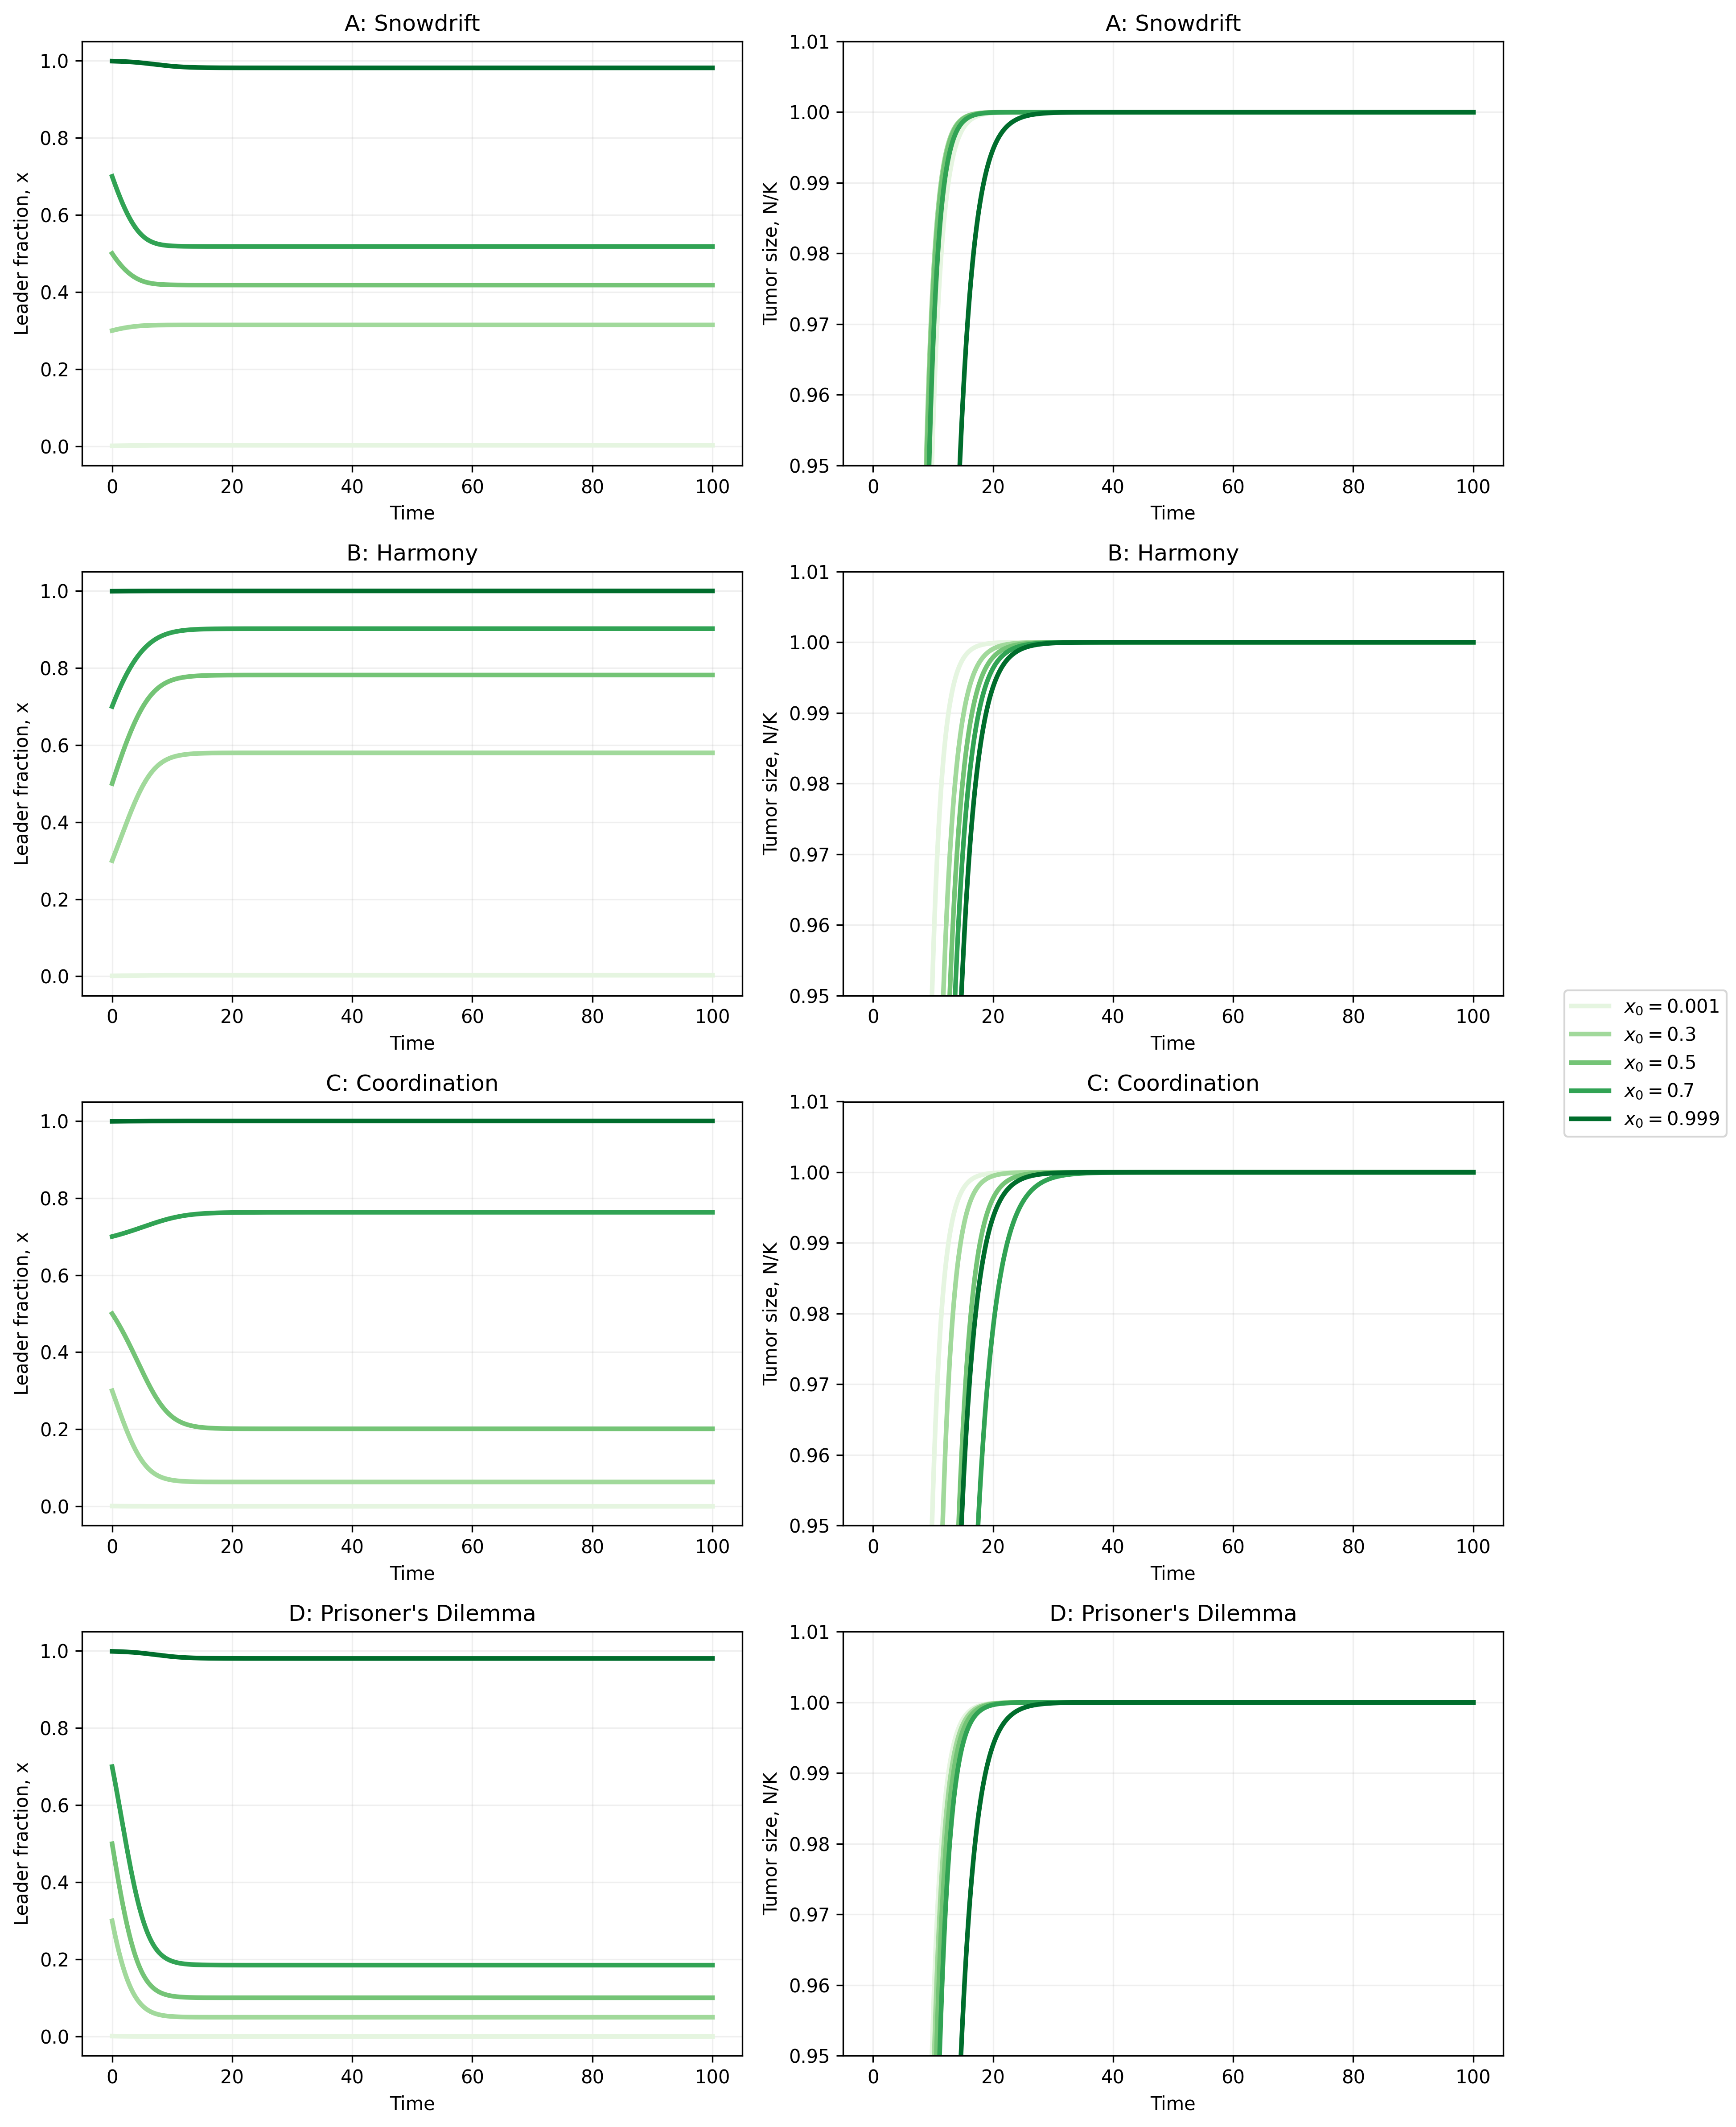

In [2]:
import numpy as np
import matplotlib.pyplot as plt

alpha, delta = 0.4, 0.6
K = 1e9
N0 = 0.5e8

x0_list = [0.001, 0.3, 0.5, 0.7, 0.999]

scenarios = [
    ("A", "Snowdrift",          0.8, 0.8),
    ("B", "Harmony",            0.8, 0.2),
    ("C", "Coordination",       0.2, 0.2),
    ("D", "Prisoner's Dilemma", 0.2, 0.8),
]

T = np.linspace(0, 100, 1001)
dt = T[1] - T[0]

colors = ["#E5F5E0", "#A1D99B", "#74C476", "#31A354", "#006D2C"]

def simulate(beta, gamma, x0, slow_evolution=True):
    def fL(x):
        return alpha * x + beta * (1 - x)

    def fF(x):
        return gamma * x + delta * (1 - x)

    def crowding(N):
        return max(0.0, 1 - N / K)

    def growth_rate(x):
        return x * fL(x) + (1 - x) * fF(x)

    def dNdt(N, x):
        return N * growth_rate(x) * crowding(N)

    def dxdt(N, x):
        selection = x * (1 - x) * (fL(x) - fF(x))

        if slow_evolution:
            return selection * crowding(N)

        return selection

    N = np.zeros_like(T)
    x = np.zeros_like(T)

    N[0] = N0
    x[0] = x0

    for i in range(1, len(T)):
        N_curr = N[i - 1]
        x_curr = x[i - 1]

        k1N = dNdt(N_curr, x_curr)
        k1x = dxdt(N_curr, x_curr)

        k2N = dNdt(
            N_curr + 0.5 * dt * k1N,
            x_curr + 0.5 * dt * k1x
        )
        k2x = dxdt(
            N_curr + 0.5 * dt * k1N,
            x_curr + 0.5 * dt * k1x
        )

        k3N = dNdt(
            N_curr + 0.5 * dt * k2N,
            x_curr + 0.5 * dt * k2x
        )
        k3x = dxdt(
            N_curr + 0.5 * dt * k2N,
            x_curr + 0.5 * dt * k2x
        )

        k4N = dNdt(
            N_curr + dt * k3N,
            x_curr + dt * k3x
        )
        k4x = dxdt(
            N_curr + dt * k3N,
            x_curr + dt * k3x
        )

        N[i] = N_curr + (dt / 6) * (k1N + 2*k2N + 2*k3N + k4N)
        x[i] = x_curr + (dt / 6) * (k1x + 2*k2x + 2*k3x + k4x)

        N[i] = max(0.0, min(N[i], K))
        x[i] = max(0.0, min(x[i], 1.0))

    return x, N

fig, axes = plt.subplots(4, 2, figsize=(13, 16), dpi=300)

for row, (code, name, beta, gamma) in enumerate(scenarios):
    ax_x = axes[row, 0]
    ax_N = axes[row, 1]

    for x0, color in zip(x0_list, colors):
        x, N = simulate(beta, gamma, x0, slow_evolution=True)

        ax_x.plot(T, x, color=color, linewidth=2.5, label=f"$x_0={x0}$")
        ax_N.plot(T, N / K, color=color, linewidth=2.5)

        print(
            f"{code} {name}, x0={x0}: "
            f"x(100)={x[-1]:.4f}, "
            f"N(100)={N[-1]:.3e}, "
            f"N(100)/K={N[-1]/K:.4f}"
        )

    ax_x.set_title(f"{code}: {name}")
    ax_N.set_title(f"{code}: {name}")

    ax_x.set_ylabel("Leader fraction, x")
    ax_N.set_ylabel("Tumor size, N/K")

    ax_x.set_xlabel("Time")
    ax_N.set_xlabel("Time")

    ax_x.set_ylim(-0.05, 1.05)
    ax_N.set_ylim(0.95, 1.01)

    ax_x.grid(alpha=0.2)
    ax_N.grid(alpha=0.2)

handles, labels = axes[0, 0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    loc="center right",
    frameon=True
)

plt.tight_layout(rect=[0, 0, 0.88, 1])
plt.show()

A Snowdrift, x0=0.001: x(100)=0.0072, N(100)=1.000e+09, N(100)/K=1.0000
A Snowdrift, x0=0.3: x(100)=0.3242, N(100)=1.000e+09, N(100)/K=1.0000
A Snowdrift, x0=0.5: x(100)=0.3722, N(100)=1.000e+09, N(100)/K=1.0000
A Snowdrift, x0=0.7: x(100)=0.4187, N(100)=1.000e+09, N(100)/K=1.0000
A Snowdrift, x0=0.999: x(100)=0.9514, N(100)=1.000e+09, N(100)/K=1.0000
B Harmony, x0=0.001: x(100)=0.0074, N(100)=1.000e+09, N(100)/K=1.0000
B Harmony, x0=0.3: x(100)=0.7606, N(100)=1.000e+09, N(100)/K=1.0000
B Harmony, x0=0.5: x(100)=0.8812, N(100)=1.000e+09, N(100)/K=1.0000
B Harmony, x0=0.7: x(100)=0.9454, N(100)=1.000e+09, N(100)/K=1.0000
B Harmony, x0=0.999: x(100)=0.9999, N(100)=1.000e+09, N(100)/K=1.0000
C Coordination, x0=0.001: x(100)=0.0000, N(100)=1.000e+09, N(100)/K=1.0000
C Coordination, x0=0.3: x(100)=0.0154, N(100)=1.000e+09, N(100)/K=1.0000
C Coordination, x0=0.5: x(100)=0.1074, N(100)=1.000e+09, N(100)/K=1.0000
C Coordination, x0=0.7: x(100)=0.7750, N(100)=1.000e+09, N(100)/K=1.0000
C Coordi

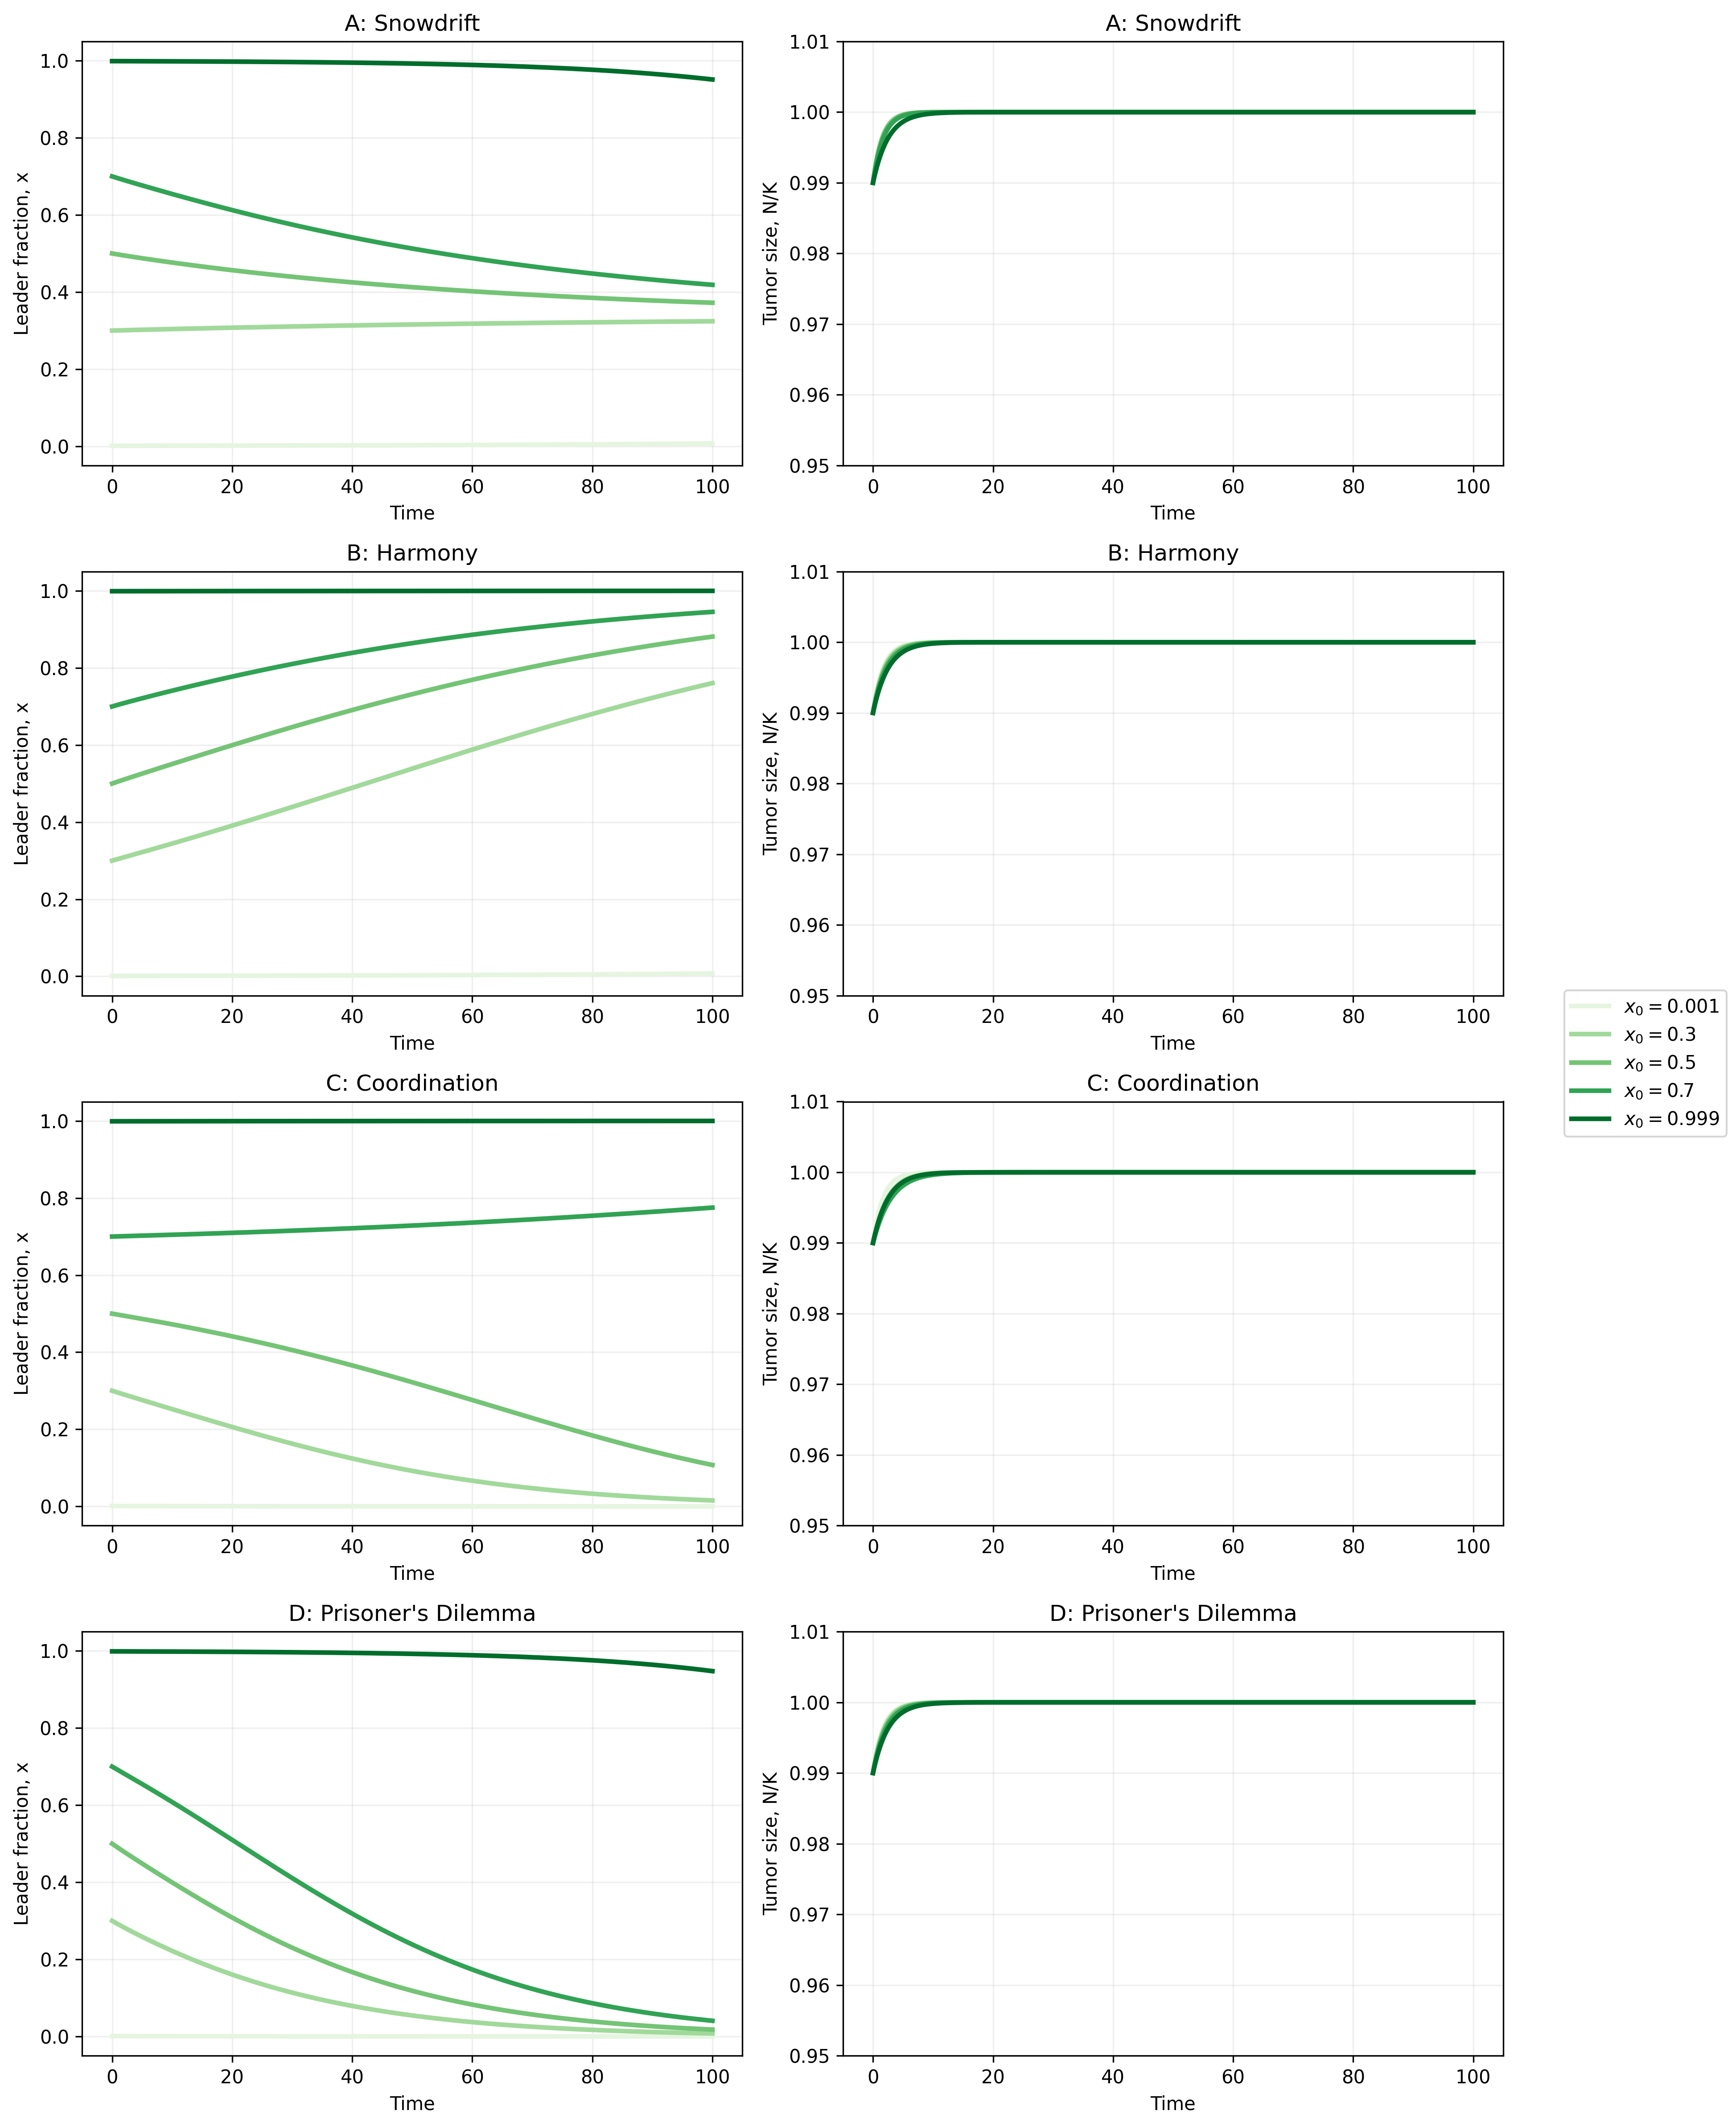

In [3]:
import numpy as np
import matplotlib.pyplot as plt

alpha, delta = 0.4, 0.6
K = 1e9
N0 = 9.9e8
rho = 0.1

x0_list = [0.001, 0.3, 0.5, 0.7, 0.999]

scenarios = [
    ("A", "Snowdrift",          0.8, 0.8),
    ("B", "Harmony",            0.8, 0.2),
    ("C", "Coordination",       0.2, 0.2),
    ("D", "Prisoner's Dilemma", 0.2, 0.8),
]

T = np.linspace(0, 100, 1001)
dt = T[1] - T[0]

colors = ["#E5F5E0", "#A1D99B", "#74C476", "#31A354", "#006D2C"]

def simulate(beta, gamma, x0):
    def fL(x):
        return alpha * x + beta * (1 - x)

    def fF(x):
        return gamma * x + delta * (1 - x)

    def crowding(N):
        return max(0.0, 1 - N / K)

    def evolution_factor(N):
        return rho + (1 - rho) * crowding(N)

    def growth_rate(x):
        return x * fL(x) + (1 - x) * fF(x)

    def dNdt(N, x):
        return N * growth_rate(x) * crowding(N)

    def dxdt(N, x):
        return x * (1 - x) * (fL(x) - fF(x)) * evolution_factor(N)

    N = np.zeros_like(T)
    x = np.zeros_like(T)

    N[0] = N0
    x[0] = x0

    for i in range(1, len(T)):
        N_curr = N[i - 1]
        x_curr = x[i - 1]

        k1N = dNdt(N_curr, x_curr)
        k1x = dxdt(N_curr, x_curr)

        k2N = dNdt(N_curr + 0.5 * dt * k1N, x_curr + 0.5 * dt * k1x)
        k2x = dxdt(N_curr + 0.5 * dt * k1N, x_curr + 0.5 * dt * k1x)

        k3N = dNdt(N_curr + 0.5 * dt * k2N, x_curr + 0.5 * dt * k2x)
        k3x = dxdt(N_curr + 0.5 * dt * k2N, x_curr + 0.5 * dt * k2x)

        k4N = dNdt(N_curr + dt * k3N, x_curr + dt * k3x)
        k4x = dxdt(N_curr + dt * k3N, x_curr + dt * k3x)

        N[i] = N_curr + (dt / 6) * (k1N + 2*k2N + 2*k3N + k4N)
        x[i] = x_curr + (dt / 6) * (k1x + 2*k2x + 2*k3x + k4x)

        N[i] = max(0.0, min(N[i], K))
        x[i] = max(0.0, min(x[i], 1.0))

    return x, N

fig, axes = plt.subplots(4, 2, figsize=(13, 16), dpi=300)

for row, (code, name, beta, gamma) in enumerate(scenarios):
    ax_x = axes[row, 0]
    ax_N = axes[row, 1]

    for x0, color in zip(x0_list, colors):
        x, N = simulate(beta, gamma, x0)

        ax_x.plot(T, x, color=color, linewidth=2.5, label=f"$x_0={x0}$")
        ax_N.plot(T, N / K, color=color, linewidth=2.5)

        print(
            f"{code} {name}, x0={x0}: "
            f"x(100)={x[-1]:.4f}, "
            f"N(100)={N[-1]:.3e}, "
            f"N(100)/K={N[-1]/K:.4f}"
        )

    ax_x.set_title(f"{code}: {name}")
    ax_N.set_title(f"{code}: {name}")

    ax_x.set_ylabel("Leader fraction, x")
    ax_N.set_ylabel("Tumor size, N/K")

    ax_x.set_xlabel("Time")
    ax_N.set_xlabel("Time")

    ax_x.set_ylim(-0.05, 1.05)
    ax_N.set_ylim(0.95, 1.01)

    ax_x.grid(alpha=0.2)
    ax_N.grid(alpha=0.2)

handles, labels = axes[0, 0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    loc="center right",
    frameon=True
)

plt.tight_layout(rect=[0, 0, 0.88, 1])
plt.show()

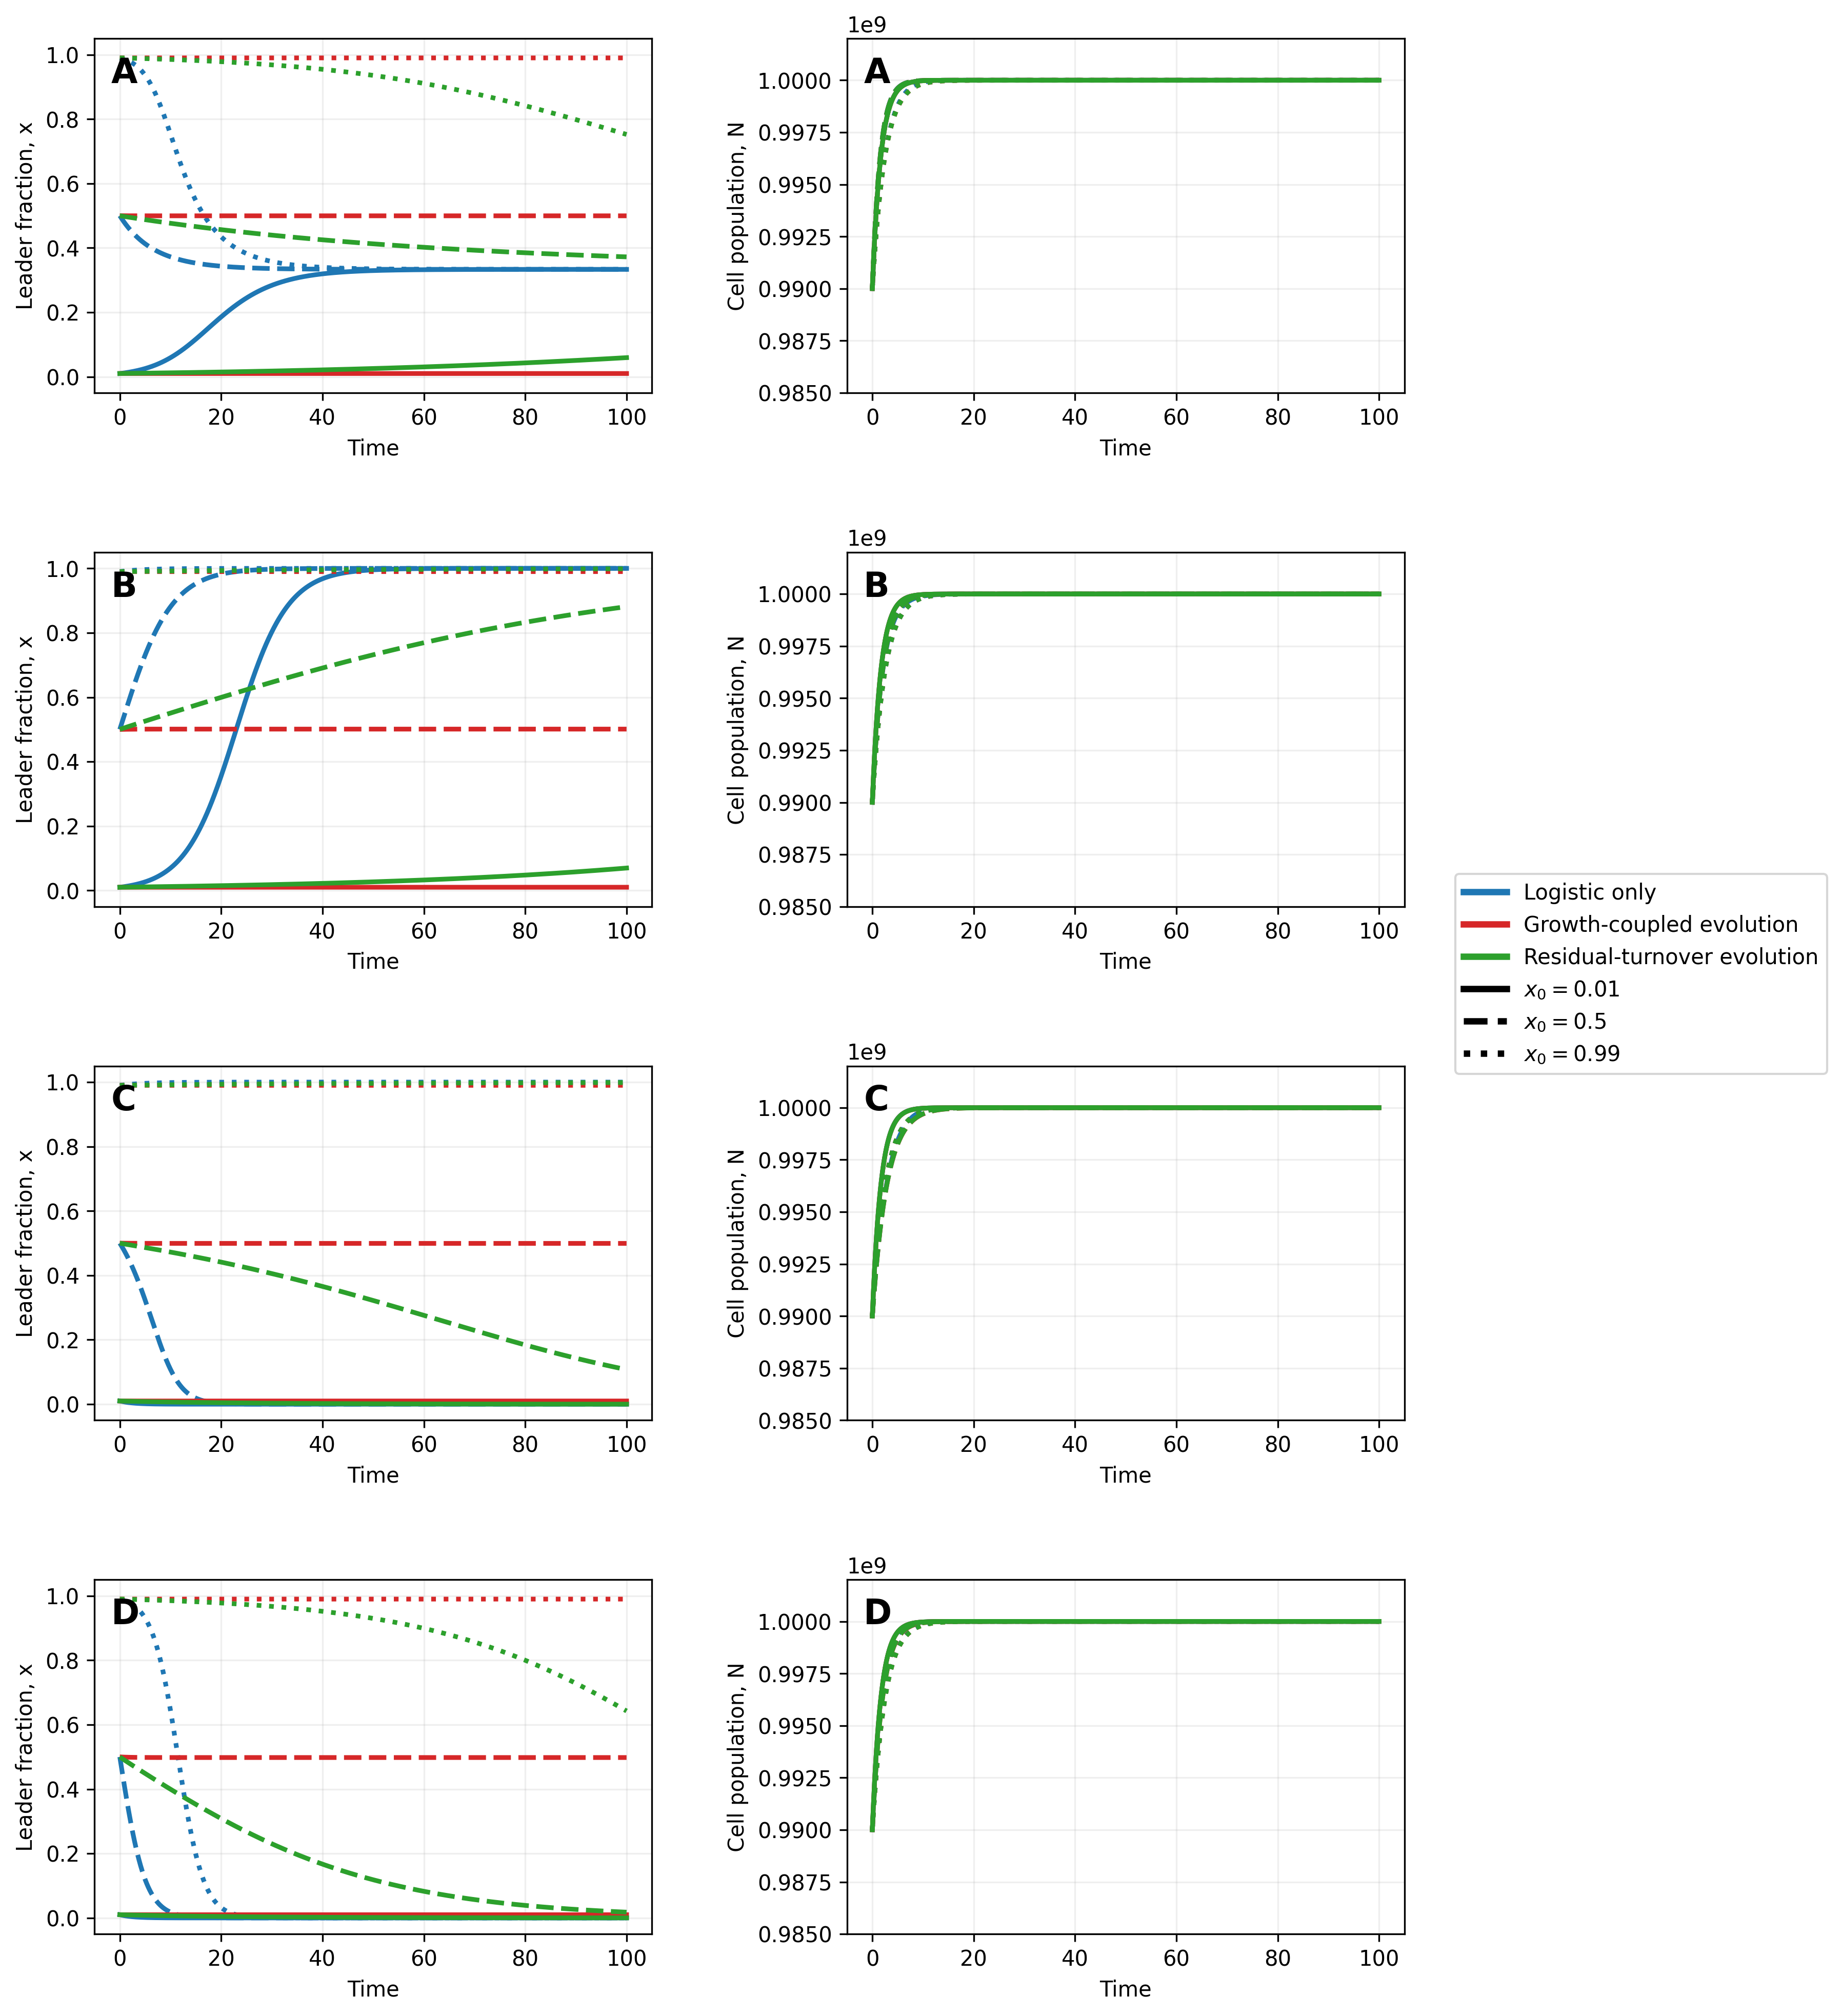

In [6]:
import numpy as np
import matplotlib.pyplot as plt

alpha, delta = 0.4, 0.6
K = 1e9
N0 = 9.9e8
rho = 0.1

x0_list = [0.01, 0.5, 0.99]

scenarios = [
    ("A", "Snowdrift",          0.8, 0.8),
    ("B", "Harmony",            0.8, 0.2),
    ("C", "Coordination",       0.2, 0.2),
    ("D", "Prisoner's Dilemma", 0.2, 0.8),
]

T = np.linspace(0, 100, 1001)
dt = T[1] - T[0]

model_colors = {
    "Logistic only": "#1f77b4",
    "Growth-coupled evolution": "#d62728",
    "Residual-turnover evolution": "#2ca02c",
}

x0_styles = {
    0.01: "-",
    0.5: "--",
    0.99: ":",
}

def simulate(beta, gamma, x0, model_type):
    def fL(x):
        return alpha * x + beta * (1 - x)

    def fF(x):
        return gamma * x + delta * (1 - x)

    def crowding(N):
        return max(0.0, 1 - N / K)

    def evolution_factor(N):
        if model_type == "Logistic only":
            return 1.0
        if model_type == "Growth-coupled evolution":
            return crowding(N)
        if model_type == "Residual-turnover evolution":
            return rho + (1 - rho) * crowding(N)
        raise ValueError(f"Unknown model type: {model_type}")

    def growth_rate(x):
        return x * fL(x) + (1 - x) * fF(x)

    def dNdt(N, x):
        return N * growth_rate(x) * crowding(N)

    def dxdt(N, x):
        return x * (1 - x) * (fL(x) - fF(x)) * evolution_factor(N)

    N = np.zeros_like(T)
    x = np.zeros_like(T)

    N[0] = N0
    x[0] = x0

    for i in range(1, len(T)):
        n = N[i - 1]
        xx = x[i - 1]

        k1N = dNdt(n, xx)
        k1x = dxdt(n, xx)

        k2N = dNdt(n + 0.5 * dt * k1N, xx + 0.5 * dt * k1x)
        k2x = dxdt(n + 0.5 * dt * k1N, xx + 0.5 * dt * k1x)

        k3N = dNdt(n + 0.5 * dt * k2N, xx + 0.5 * dt * k2x)
        k3x = dxdt(n + 0.5 * dt * k2N, xx + 0.5 * dt * k2x)

        k4N = dNdt(n + dt * k3N, xx + dt * k3x)
        k4x = dxdt(n + dt * k3N, xx + dt * k3x)

        N[i] = n + (dt / 6) * (k1N + 2*k2N + 2*k3N + k4N)
        x[i] = xx + (dt / 6) * (k1x + 2*k2x + 2*k3x + k4x)

        N[i] = max(0.0, min(N[i], K))
        x[i] = max(0.0, min(x[i], 1.0))

    return x, N

fig, axes = plt.subplots(4, 2, figsize=(13, 16), dpi=300)
fig.subplots_adjust(right=0.78, hspace=0.45, wspace=0.35)

model_types = list(model_colors.keys())

for row, (code, name, beta, gamma) in enumerate(scenarios):
    ax_x = axes[row, 0]
    ax_N = axes[row, 1]

    for model_type in model_types:
        for x0 in x0_list:
            x, N = simulate(beta, gamma, x0, model_type)

            ax_x.plot(
                T, x,
                color=model_colors[model_type],
                linestyle=x0_styles[x0],
                linewidth=2.2,
            )

            ax_N.plot(
                T, N,
                color=model_colors[model_type],
                linestyle=x0_styles[x0],
                linewidth=2.2,
            )

    ax_x.text(
        0.03, 0.95, code,
        transform=ax_x.transAxes,
        fontsize=16,
        fontweight="bold",
        va="top",
        ha="left"
    )

    ax_N.text(
        0.03, 0.95, code,
        transform=ax_N.transAxes,
        fontsize=16,
        fontweight="bold",
        va="top",
        ha="left"
    )

    ax_x.set_ylabel("Leader fraction, x")
    ax_N.set_ylabel("Cell population, N")

    ax_x.set_xlabel("Time")
    ax_N.set_xlabel("Time")

    ax_x.set_ylim(-0.05, 1.05)
    ax_N.set_ylim(0.985 * K, 1.002 * K)

    ax_x.grid(alpha=0.2)
    ax_N.grid(alpha=0.2)

model_handles = [
    plt.Line2D([0], [0], color=color, linewidth=3, linestyle="-")
    for color in model_colors.values()
]

x0_handles = [
    plt.Line2D([0], [0], color="black", linewidth=3, linestyle=x0_styles[x0])
    for x0 in x0_list
]

fig.legend(
    model_handles + x0_handles,
    list(model_colors.keys()) + [f"$x_0={x0}$" for x0 in x0_list],
    loc="center left",
    bbox_to_anchor=(0.80, 0.50),
    frameon=True,
)

plt.show()

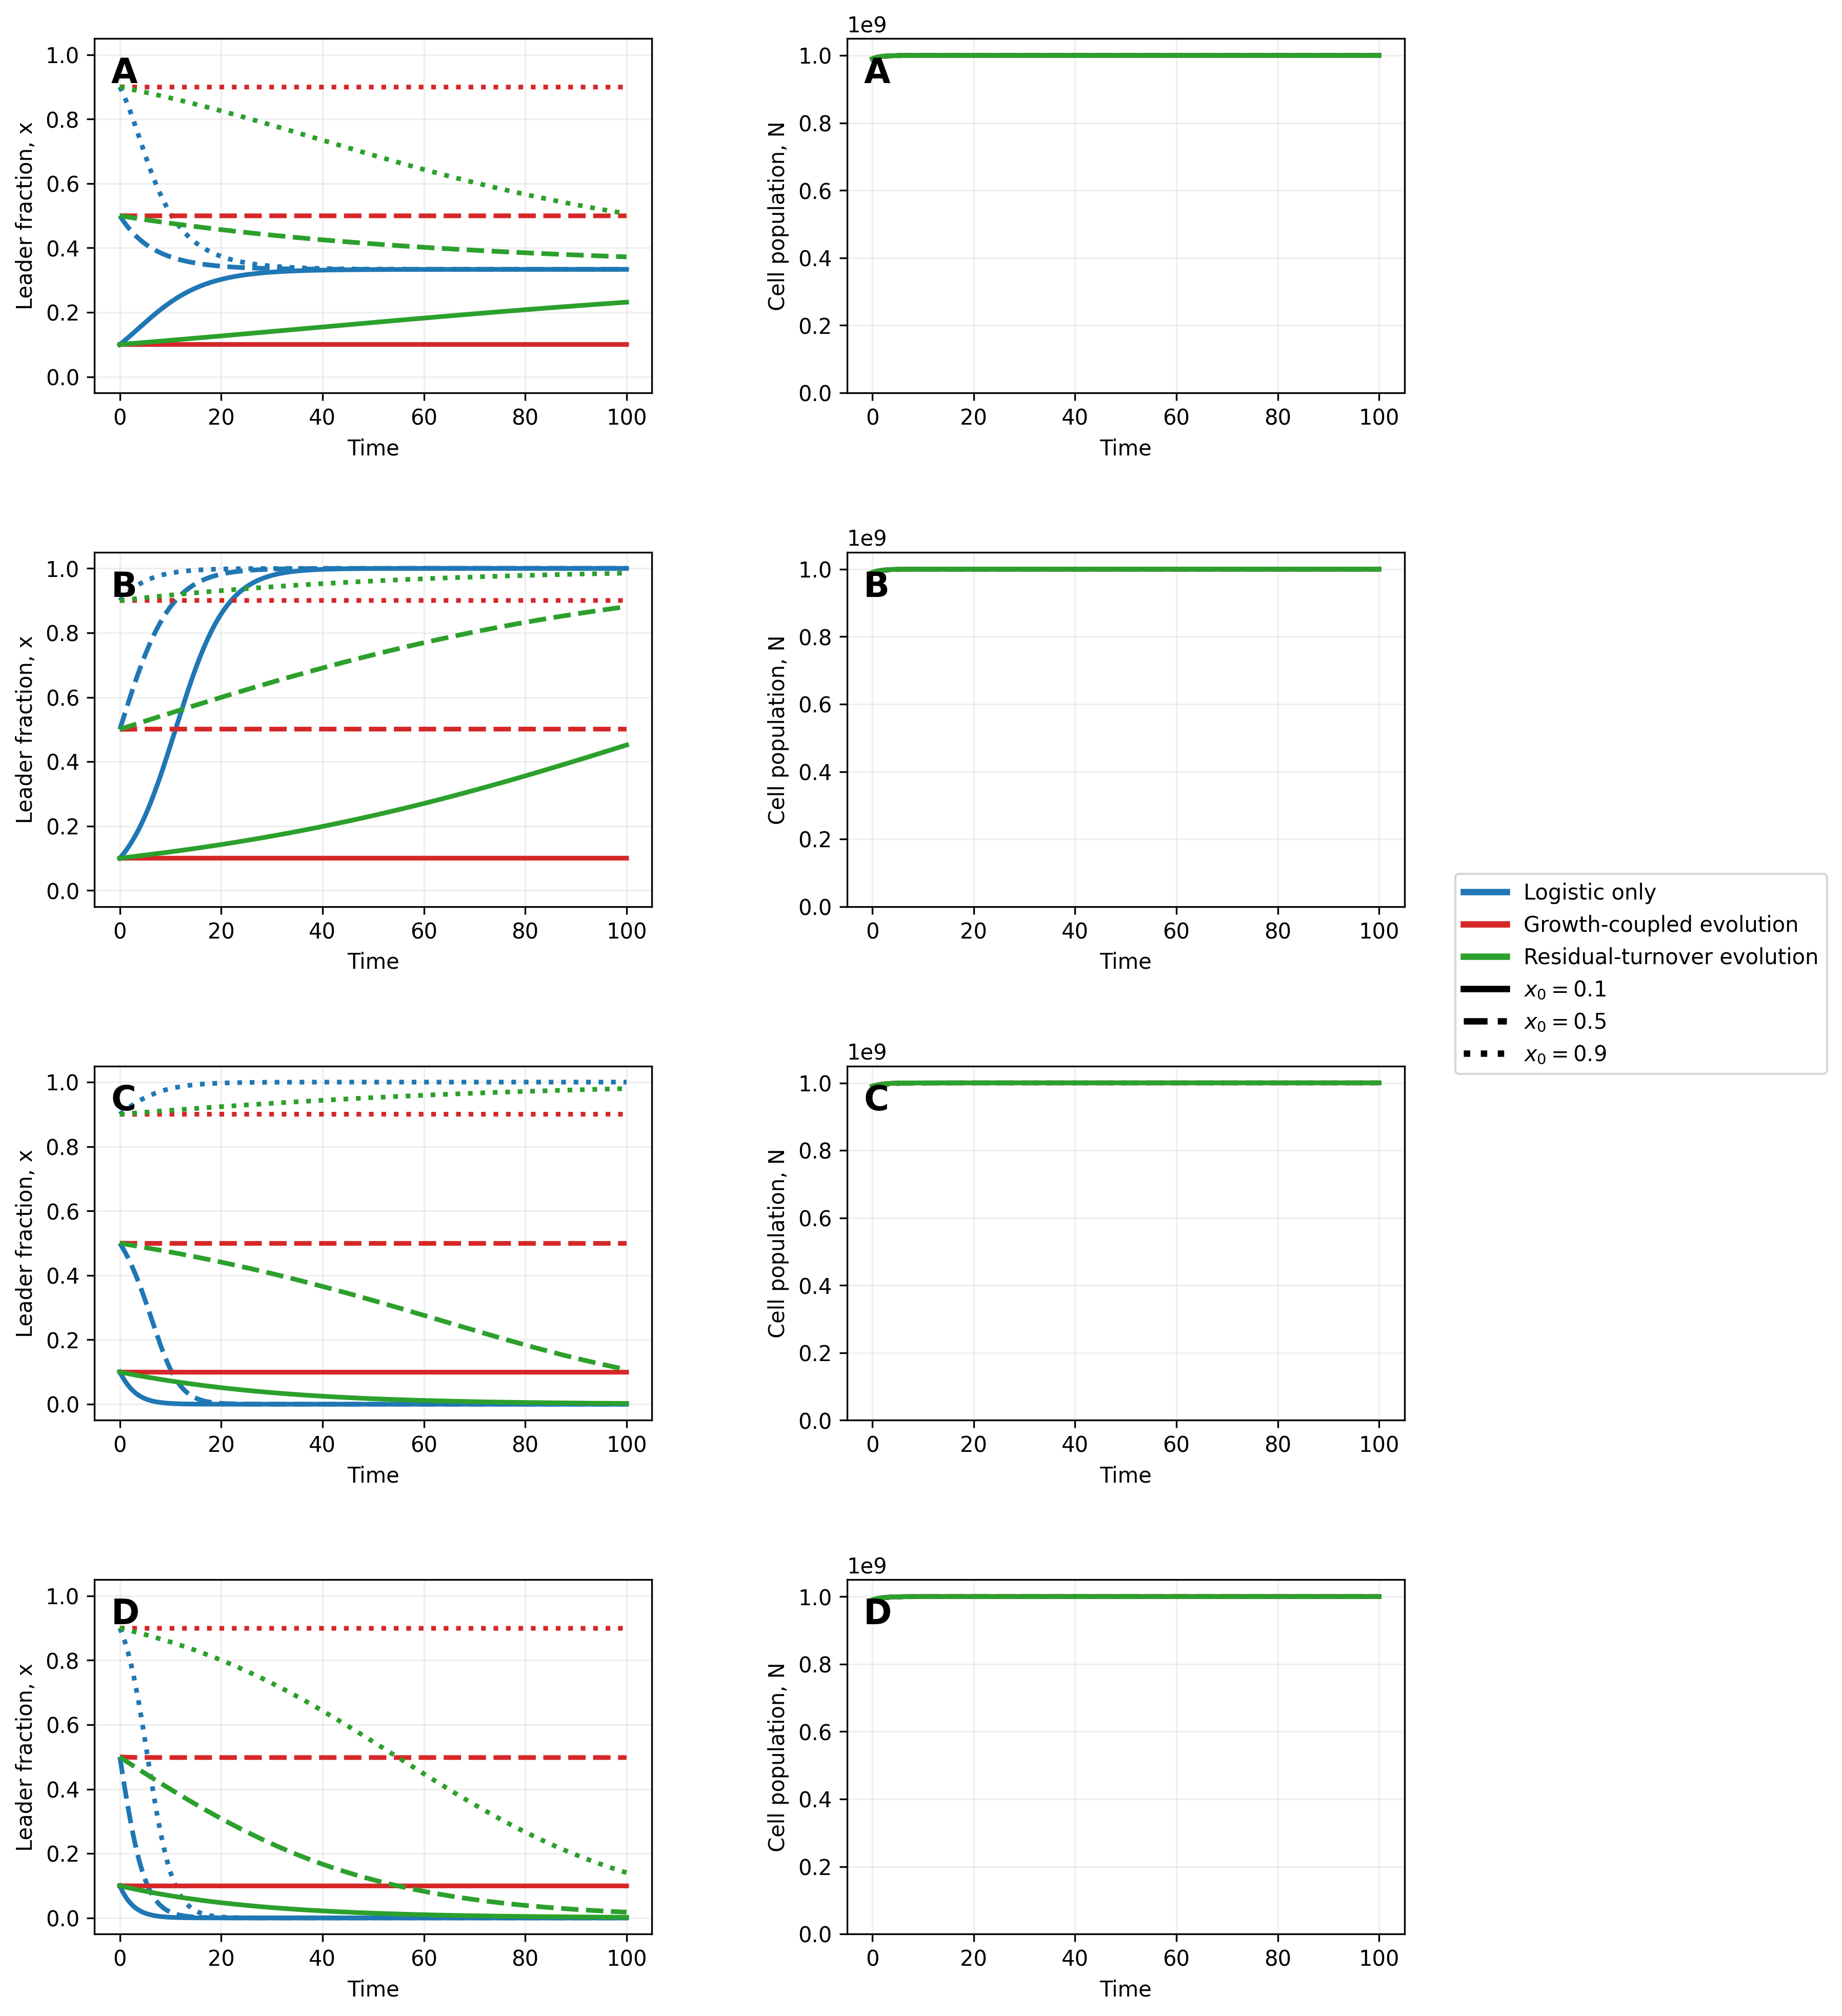

In [14]:
import numpy as np
import matplotlib.pyplot as plt

alpha, delta = 0.4, 0.6
K = 1e9
N0 = 9.9e8
rho = 0.1

x0_list = [0.1, 0.5, 0.9]

scenarios = [
    ("A", "Snowdrift",          0.8, 0.8),
    ("B", "Harmony",            0.8, 0.2),
    ("C", "Coordination",       0.2, 0.2),
    ("D", "Prisoner's Dilemma", 0.2, 0.8),
]

T = np.linspace(0, 100, 1001)
dt = T[1] - T[0]

model_colors = {
    "Logistic only": "#1f77b4",
    "Growth-coupled evolution": "#d62728",
    "Residual-turnover evolution": "#2ca02c",
}

x0_styles = {
    0.1: "-",
    0.5: "--",
    0.9: ":",
}

def simulate(beta, gamma, x0, model_type):
    def fL(x):
        return alpha * x + beta * (1 - x)

    def fF(x):
        return gamma * x + delta * (1 - x)

    def crowding(N):
        return max(0.0, 1 - N / K)

    def evolution_factor(N):
        if model_type == "Logistic only":
            return 1.0
        if model_type == "Growth-coupled evolution":
            return crowding(N)
        if model_type == "Residual-turnover evolution":
            return rho + (1 - rho) * crowding(N)
        raise ValueError(f"Unknown model type: {model_type}")

    def growth_rate(x):
        return x * fL(x) + (1 - x) * fF(x)

    def dNdt(N, x):
        return N * growth_rate(x) * crowding(N)

    def dxdt(N, x):
        return x * (1 - x) * (fL(x) - fF(x)) * evolution_factor(N)

    N = np.zeros_like(T)
    x = np.zeros_like(T)

    N[0] = N0
    x[0] = x0

    for i in range(1, len(T)):
        n = N[i - 1]
        xx = x[i - 1]

        k1N = dNdt(n, xx)
        k1x = dxdt(n, xx)

        k2N = dNdt(n + 0.5 * dt * k1N, xx + 0.5 * dt * k1x)
        k2x = dxdt(n + 0.5 * dt * k1N, xx + 0.5 * dt * k1x)

        k3N = dNdt(n + 0.5 * dt * k2N, xx + 0.5 * dt * k2x)
        k3x = dxdt(n + 0.5 * dt * k2N, xx + 0.5 * dt * k2x)

        k4N = dNdt(n + dt * k3N, xx + dt * k3x)
        k4x = dxdt(n + dt * k3N, xx + dt * k3x)

        N[i] = n + (dt / 6) * (k1N + 2*k2N + 2*k3N + k4N)
        x[i] = xx + (dt / 6) * (k1x + 2*k2x + 2*k3x + k4x)

        N[i] = max(0.0, min(N[i], K))
        x[i] = max(0.0, min(x[i], 1.0))

    return x, N

fig, axes = plt.subplots(4, 2, figsize=(13, 16), dpi=300)
fig.subplots_adjust(right=0.78, hspace=0.45, wspace=0.35)

model_types = list(model_colors.keys())

for row, (code, name, beta, gamma) in enumerate(scenarios):
    ax_x = axes[row, 0]
    ax_N = axes[row, 1]

    for model_type in model_types:
        for x0 in x0_list:
            x, N = simulate(beta, gamma, x0, model_type)

            ax_x.plot(
                T, x,
                color=model_colors[model_type],
                linestyle=x0_styles[x0],
                linewidth=2.2,
            )

            ax_N.plot(
                T, N,
                color=model_colors[model_type],
                linestyle=x0_styles[x0],
                linewidth=2.2,
            )

    ax_x.text(
        0.03, 0.95, code,
        transform=ax_x.transAxes,
        fontsize=16,
        fontweight="bold",
        va="top",
        ha="left"
    )

    ax_N.text(
        0.03, 0.95, code,
        transform=ax_N.transAxes,
        fontsize=16,
        fontweight="bold",
        va="top",
        ha="left"
    )

    ax_x.set_ylabel("Leader fraction, x")
    ax_N.set_ylabel("Cell population, N")

    ax_x.set_xlabel("Time")
    ax_N.set_xlabel("Time")

    ax_x.set_ylim(-0.05, 1.05)
    ax_N.set_ylim(0, 1.05 * K)
    ax_N.ticklabel_format(axis="y", style="sci", scilimits=(0, 0))

    ax_x.grid(alpha=0.2)
    ax_N.grid(alpha=0.2)

model_handles = [
    plt.Line2D([0], [0], color=color, linewidth=3, linestyle="-")
    for color in model_colors.values()
]

x0_handles = [
    plt.Line2D([0], [0], color="black", linewidth=3, linestyle=x0_styles[x0])
    for x0 in x0_list
]

fig.legend(
    model_handles + x0_handles,
    list(model_colors.keys()) + [f"$x_0={x0}$" for x0 in x0_list],
    loc="center left",
    bbox_to_anchor=(0.80, 0.50),
    frameon=True,
)

plt.show()

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

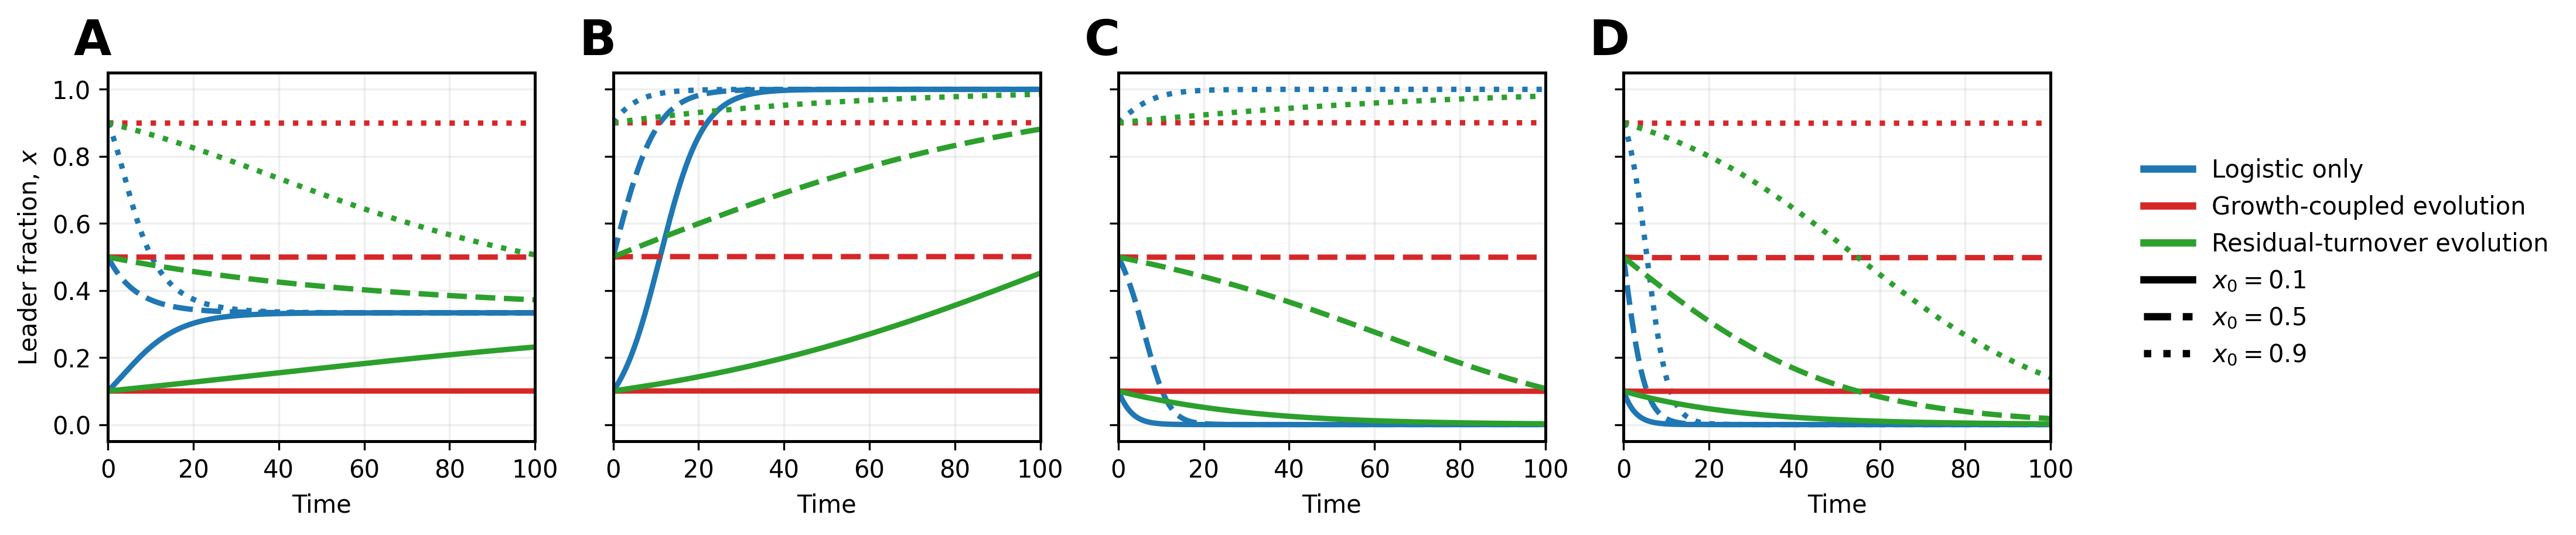

In [15]:
fig, axes = plt.subplots(
    1, 4,
    figsize=(12, 3.2),
    dpi=300,
    sharey=True
)

for col, (code, name, beta, gamma) in enumerate(scenarios):

    ax = axes[col]

    for model_type in model_types:
        for x0 in x0_list:

            x, N = simulate(beta, gamma, x0, model_type)

            ax.plot(
                T,
                x,
                color=model_colors[model_type],
                linestyle=x0_styles[x0],
                linewidth=2.2,
            )

    ax.text(
        -0.08,
        1.15,
        code,
        transform=ax.transAxes,
        fontsize=20,
        fontweight='bold',
        va='top',
        ha='left'
    )

    ax.set_xlabel("Time")

    if col == 0:
        ax.set_ylabel("Leader fraction, $x$")

    ax.set_ylim(-0.05, 1.05)
    ax.set_xlim(0, 100)

    ax.grid(alpha=0.2)

    for spine in ax.spines.values():
        spine.set_linewidth(1.2)

model_handles = [
    plt.Line2D([0], [0],
               color=color,
               linewidth=3,
               linestyle='-')
    for color in model_colors.values()
]

x0_handles = [
    plt.Line2D([0], [0],
               color='black',
               linewidth=3,
               linestyle=x0_styles[x0])
    for x0 in x0_list
]

fig.legend(
    model_handles + x0_handles,
    list(model_colors.keys()) +
    [f"$x_0={x0}$" for x0 in x0_list],
    loc='center left',
    bbox_to_anchor=(1.01, 0.5),
    frameon=False,
    fontsize=10
)

plt.tight_layout()

plt.savefig(
    "sfig3a.png",
    dpi=600,
    bbox_inches="tight",
    facecolor="white"
)

from google.colab import files
files.download("sfig3a.png")

plt.show()

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

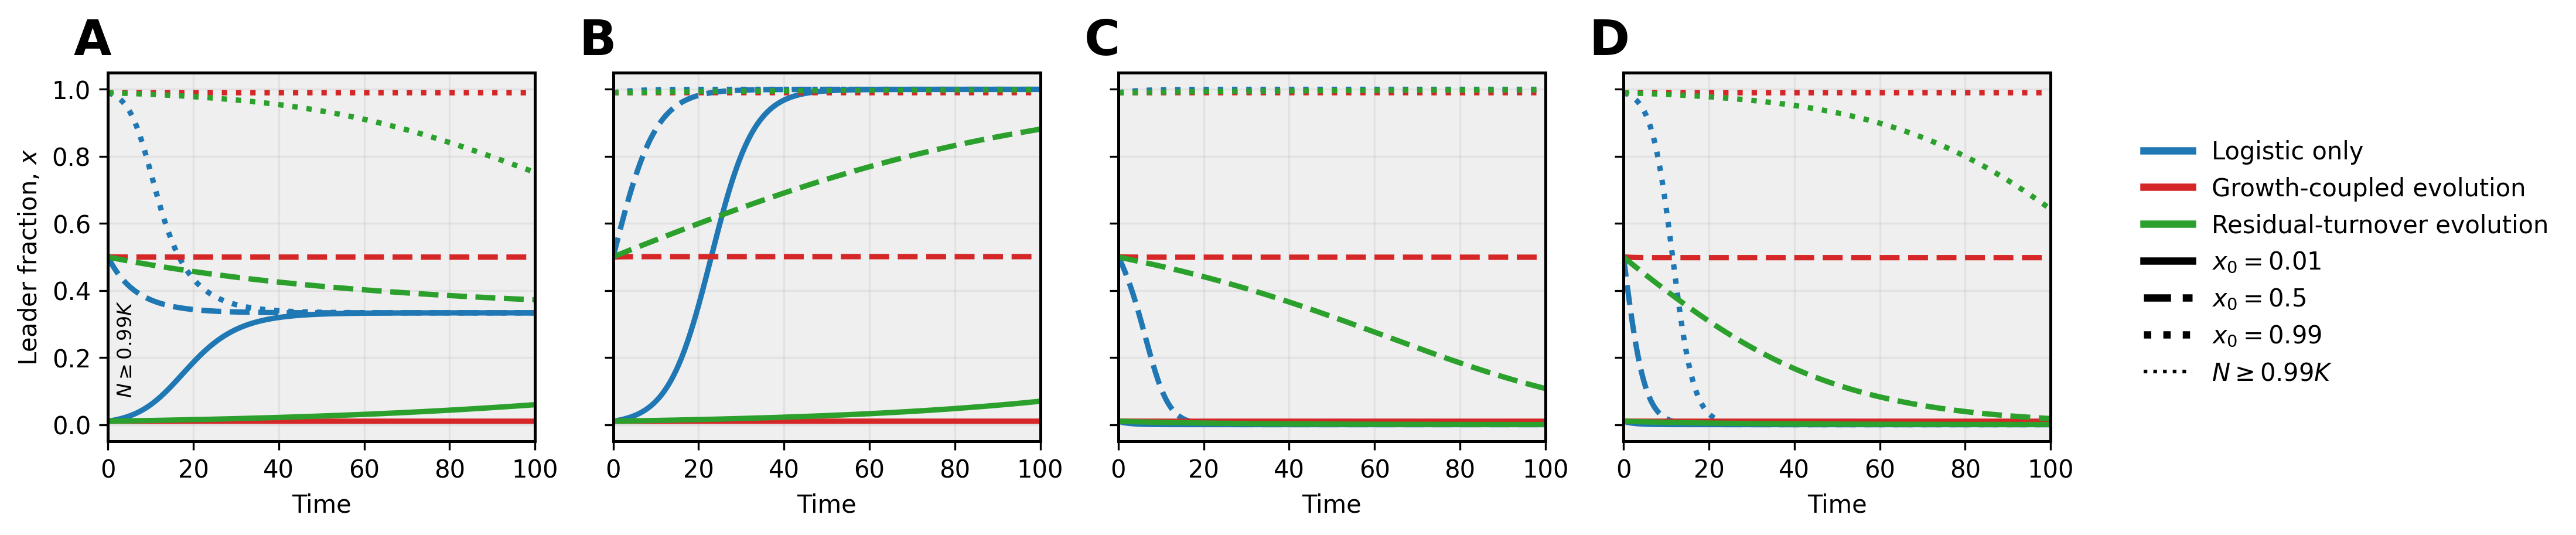

In [12]:
fig, axes = plt.subplots(
    1, 4,
    figsize=(12, 3.2),
    dpi=300,
    sharey=True
)

sat_threshold = 0.99

for col, (code, name, beta, gamma) in enumerate(scenarios):

    ax = axes[col]
    t_sat_all = []

    for model_type in model_types:
        for x0 in x0_list:

            x, N = simulate(beta, gamma, x0, model_type)

            ax.plot(
                T,
                x,
                color=model_colors[model_type],
                linestyle=x0_styles[x0],
                linewidth=2.2,
            )

            idx_sat = np.where(N >= sat_threshold * K)[0]
            if len(idx_sat) > 0:
                t_sat_all.append(T[idx_sat[0]])

    if len(t_sat_all) > 0:
        t_sat = min(t_sat_all)

        ax.axvspan(
            t_sat,
            T[-1],
            color="gray",
            alpha=0.12,
            linewidth=0
        )

        ax.axvline(
            t_sat,
            color="black",
            linestyle=":",
            linewidth=1.2,
            alpha=0.8
        )

        if col == 0:
            ax.text(
                t_sat + 2,
                0.08,
                r"$N \geq 0.99K$",
                rotation=90,
                fontsize=8,
                va="bottom",
                ha="left"
            )

    ax.text(
        -0.08,
        1.15,
        code,
        transform=ax.transAxes,
        fontsize=20,
        fontweight="bold",
        va="top",
        ha="left"
    )

    ax.set_xlabel("Time")

    if col == 0:
        ax.set_ylabel("Leader fraction, $x$")

    ax.set_ylim(-0.05, 1.05)
    ax.set_xlim(0, 100)

    ax.grid(alpha=0.2)

    for spine in ax.spines.values():
        spine.set_linewidth(1.2)

model_handles = [
    plt.Line2D(
        [0], [0],
        color=color,
        linewidth=3,
        linestyle="-"
    )
    for color in model_colors.values()
]

x0_handles = [
    plt.Line2D(
        [0], [0],
        color="black",
        linewidth=3,
        linestyle=x0_styles[x0]
    )
    for x0 in x0_list
]

sat_handle = plt.Line2D(
    [0], [0],
    color="black",
    linestyle=":",
    linewidth=1.5
)

fig.legend(
    model_handles + x0_handles + [sat_handle],
    list(model_colors.keys()) +
    [f"$x_0={x0}$" for x0 in x0_list] +
    [r"$N \geq 0.99K$"],
    loc="center left",
    bbox_to_anchor=(1.01, 0.5),
    frameon=False,
    fontsize=10
)

plt.tight_layout()

plt.savefig(
    "sfig3a.png",
    dpi=600,
    bbox_inches="tight",
    facecolor="white"
)

from google.colab import files
files.download("sfig3a.png")

plt.show()